# Домашнє завдання 2. ER-модель, DDL, нормалізація та point-in-time correctness

Mykyta Oliinyk

## Сценарій

Сервіс доставки їжі. У момент призначення кур'єра на замовлення модель прогнозує, чи буде доставка пізнішою за обіцяний клієнту час. Прогноз допомагає диспетчеру обрати іншого кур'єра або чесно збільшити ETA.

- entity feature store: `courier_id`;
- момент прогнозу: `prediction_ts`, час призначення кур'єра;
- цільова змінна: `is_late`, тобто `delivered_at > promised_at`;
- ознаки: 30-денна статистика кур'єра, яку пакетна задача публікує о 06:00 UTC.

`valid_from` у цій схемі означає момент публікації версії, коли її вже можна прочитати. Ознаки рахуються лише за подіями до цього моменту. Саме тому умова `valid_from <= prediction_ts` відтинає майбутнє.

Дані синтетичні й записані вручну через `INSERT`, зовнішній датасет не потрібен. `hw2_orders` містить лише невелику вибірку, а значення ознак відображають ширшу історію кур'єра, тому вони не перераховуються з цих 14 замовлень.

## Setup

PostgreSQL запускається через `pgserver` у `/tmp/hw2_pg`. Опція `timezone=UTC` задається на рівні engine, бо `SET TIME ZONE` діє лише в межах одного з'єднання, а кожна клітинка може отримати інше.

In [1]:
%%capture
%pip install -q pgserver psycopg2-binary "psycopg[binary]" sqlalchemy pandas matplotlib

In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import pgserver
from IPython.display import Image, display
from sqlalchemy import create_engine, text
from sqlalchemy.exc import IntegrityError

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 200)
pd.set_option('display.max_colwidth', None)

pg = pgserver.get_server('/tmp/hw2_pg', cleanup_mode='stop')
engine = create_engine(
    pg.get_uri(),
    future=True,
    connect_args={'options': '-c timezone=UTC'},
)

with engine.connect() as conn:
    version = conn.execute(text('SELECT version()')).scalar_one()
    timezone = conn.execute(text('SHOW timezone')).scalar_one()
print(version)
print('timezone:', timezone)


def sql_run(statement):
    """Виконує DDL/DML, зокрема кілька команд в одному рядку, в одній транзакції."""
    with engine.begin() as conn:
        conn.execution_options(no_parameters=True).exec_driver_sql(statement)


def fetch(conn, statement):
    """Читає SELECT у DataFrame. Лічильник лишається цілим навіть за наявності NULL."""
    frame = pd.read_sql_query(text(statement), conn)
    if 'deliveries_30d' in frame:
        frame['deliveries_30d'] = frame['deliveries_30d'].astype('Int64')
    return frame


def sql_df(statement):
    """Повертає результат SELECT як DataFrame."""
    with engine.connect() as conn:
        return fetch(conn, statement)

PostgreSQL 16.2 on x86_64-pc-linux-gnu, compiled by gcc (GCC) 10.2.1 20210130 (Red Hat 10.2.1-11), 64-bit
timezone: UTC


Скидання схеми для відтворюваного повторного запуску.

In [3]:
sql_run("""
SET TIME ZONE 'UTC';

DROP TABLE IF EXISTS
    hw2_courier_features_online,
    hw2_training_events,
    hw2_courier_features_offline,
    hw2_orders,
    hw2_courier_zones,
    hw2_couriers,
    hw2_restaurants,
    hw2_zones
CASCADE;
""")
print('schema reset')

schema reset


## Завдання 1. ER-діаграма

Опис нижче є єдиним джерелом для PNG, SVG і DBML: колонки й кардинальності на діаграмі беруться з `ER_TABLES` і `ER_REFS`. Після виконання DDL окрема клітинка порівнює цей опис із каталогом PostgreSQL, тому діаграма не може розійтися зі схемою непомітно.

Позначка на лінії стоїть біля таблиці, рядки якої рахує. Наприклад, `1..1` біля `hw2_restaurants` означає один ресторан на замовлення, а `0..N` біля `hw2_orders` означає нуль або багато замовлень на ресторан.

- Бізнес-сутності: `hw2_zones`, `hw2_restaurants`, `hw2_couriers`, `hw2_orders`, bridge-таблиця `hw2_courier_zones`.
- Offline-рівень: `hw2_courier_features_offline` з `valid_from` / `valid_to`, `hw2_training_events` з `prediction_ts` і `is_late`.
- Online-рівень: `hw2_courier_features_online`.

**Зв'язок M:N.** Кур'єр сертифікований на кілька зон, а зону обслуговує кілька кур'єрів. Це природний M:N, реалізований через `hw2_courier_zones`. Таблиця має власні атрибути `certified_on` і `priority`, які не належать ні кур'єру, ні зоні окремо. Поле `priority` задає порядок зон кур'єра: 1 відповідає домашній зоні, більші значення означають резервні зони.

In [4]:
# @title Опис ER-моделі: таблиці, колонки, зв'язки
# Формат колонки: (назва, тип, позначки). NULL означає, що колонка допускає NULL.
# uniques: складені UNIQUE, одиночні позначені UQ у колонці.
ER_TABLES = {
    'hw2_zones': {'layer': 'business', 'pos': (6.0, 1.5), 'uniques': [('city', 'zone_name')], 'columns': [
        ('zone_id', 'INTEGER', 'PK'),
        ('zone_name', 'VARCHAR(60)', ''),
        ('city', 'VARCHAR(60)', ''),
        ('base_eta_min', 'INTEGER', ''),
        ('is_active', 'BOOLEAN', ''),
    ]},
    'hw2_restaurants': {'layer': 'business', 'pos': (0.7, 1.5), 'columns': [
        ('restaurant_id', 'BIGINT', 'PK'),
        ('zone_id', 'INTEGER', 'FK'),
        ('restaurant_name', 'TEXT', ''),
        ('cuisine', 'TEXT', ''),
        ('partner_since', 'DATE', ''),
    ]},
    'hw2_couriers': {'layer': 'business', 'pos': (16.6, 1.5), 'columns': [
        ('courier_id', 'BIGINT', 'PK'),
        ('home_zone_id', 'INTEGER', 'FK'),
        ('courier_code', 'VARCHAR(12)', 'UQ'),
        ('vehicle_type', 'TEXT', ''),
        ('hired_on', 'DATE', ''),
        ('is_active', 'BOOLEAN', ''),
    ]},
    'hw2_courier_zones': {'layer': 'business', 'pos': (11.3, 1.5), 'columns': [
        ('courier_id', 'BIGINT', 'PK,FK'),
        ('zone_id', 'INTEGER', 'PK,FK'),
        ('certified_on', 'DATE', ''),
        ('priority', 'INTEGER', ''),
    ]},
    'hw2_orders': {'layer': 'business', 'pos': (6.0, 4.35), 'uniques': [('order_id', 'courier_id')], 'columns': [
        ('order_id', 'BIGINT', 'PK'),
        ('restaurant_id', 'BIGINT', 'FK'),
        ('dropoff_zone_id', 'INTEGER', 'FK'),
        ('courier_id', 'BIGINT', 'FK,NULL'),
        ('created_at', 'TIMESTAMPTZ', ''),
        ('promised_at', 'TIMESTAMPTZ', ''),
        ('delivered_at', 'TIMESTAMPTZ', 'NULL'),
        ('distance_km', 'NUMERIC(6,2)', ''),
        ('order_value', 'NUMERIC(10,2)', ''),
    ]},
    'hw2_courier_features_offline': {'layer': 'offline', 'pos': (11.3, 8.75), 'columns': [
        ('courier_id', 'BIGINT', 'PK,FK'),
        ('deliveries_30d', 'INTEGER', ''),
        ('on_time_rate_30d', 'NUMERIC(5,4)', 'NULL'),
        ('avg_delivery_min_30d', 'NUMERIC(6,2)', 'NULL'),
        ('reliability_tier', 'TEXT', 'NULL'),
        ('valid_from', 'TIMESTAMPTZ', 'PK'),
        ('valid_to', 'TIMESTAMPTZ', 'NULL'),
    ]},
    'hw2_training_events': {'layer': 'offline', 'pos': (6.0, 8.75), 'columns': [
        ('event_id', 'BIGINT', 'PK'),
        ('order_id', 'BIGINT', 'FK,UQ'),
        ('courier_id', 'BIGINT', 'FK'),
        ('prediction_ts', 'TIMESTAMPTZ', ''),
        ('label_horizon_end', 'TIMESTAMPTZ', ''),
        ('is_late', 'BOOLEAN', ''),
    ]},
    'hw2_courier_features_online': {'layer': 'online', 'pos': (16.6, 8.75), 'columns': [
        ('courier_id', 'BIGINT', 'PK,FK'),
        ('home_zone_name', 'VARCHAR(60)', ''),
        ('vehicle_type', 'TEXT', ''),
        ('deliveries_30d', 'INTEGER', ''),
        ('on_time_rate_30d', 'NUMERIC(5,4)', 'NULL'),
        ('avg_delivery_min_30d', 'NUMERIC(6,2)', 'NULL'),
        ('reliability_tier', 'TEXT', 'NULL'),
        ('feature_ts', 'TIMESTAMPTZ', ''),
        ('updated_at', 'TIMESTAMPTZ', ''),
    ]},
}

# child, FK-колонки, parent, колонки parent, кардинальність на боці child і parent, сенс
ER_REFS = [
    ('hw2_restaurants', 'zone_id', 'hw2_zones', 'zone_id', '0..N', '1..1',
     'ресторан розташований в одній зоні'),
    ('hw2_couriers', 'home_zone_id', 'hw2_zones', 'zone_id', '0..N', '1..1',
     'кур\'єр має одну домашню зону'),
    ('hw2_courier_zones', 'courier_id', 'hw2_couriers', 'courier_id', '0..N', '1..1',
     'половина M:N: зони, де кур\'єр сертифікований'),
    ('hw2_courier_zones', 'zone_id', 'hw2_zones', 'zone_id', '0..N', '1..1',
     'половина M:N: кур\'єри, що обслуговують зону'),
    ('hw2_orders', 'restaurant_id', 'hw2_restaurants', 'restaurant_id', '0..N', '1..1',
     'замовлення зроблене в одному ресторані'),
    ('hw2_orders', 'dropoff_zone_id', 'hw2_zones', 'zone_id', '0..N', '1..1',
     'адреса доставки лежить в одній зоні'),
    ('hw2_orders', 'courier_id', 'hw2_couriers', 'courier_id', '0..N', '0..1',
     'кур\'єра може ще не бути або замовлення скасовано'),
    ('hw2_courier_features_offline', 'courier_id', 'hw2_couriers', 'courier_id', '0..N', '1..1',
     'історія версій ознак кур\'єра'),
    ('hw2_training_events', 'courier_id', 'hw2_couriers', 'courier_id', '0..N', '1..1',
     'кур\'єр, для якого робився прогноз'),
    ('hw2_training_events', ('order_id', 'courier_id'), 'hw2_orders', ('order_id', 'courier_id'), '0..1', '1..1',
     'одна подія на замовлення, кур\'єр збігається з замовленням'),
    ('hw2_courier_features_online', 'courier_id', 'hw2_couriers', 'courier_id', '0..1', '1..1',
     'поточний рядок ознак кур\'єра'),
]


def as_cols(value):
    return (value,) if isinstance(value, str) else value


display(pd.DataFrame(
    [
        {
            'child': child,
            'fk': ', '.join(as_cols(fk)),
            'parent': parent,
            'cardinality child : parent': f'{child_card} : {parent_card}',
            'обов\'язковість parent': 'обов\'язковий' if parent_card == '1..1' else 'необов\'язковий',
            'сенс': meaning,
        }
        for child, fk, parent, _, child_card, parent_card, meaning in ER_REFS
    ]
))

,child,fk,parent,cardinality child : parent,обов'язковість parent,сенс
0,hw2_restaurants,zone_id,hw2_zones,0..N : 1..1,обов'язковий,ресторан розташований в одній зоні
1,hw2_couriers,home_zone_id,hw2_zones,0..N : 1..1,обов'язковий,кур'єр має одну домашню зону
2,hw2_courier_zones,courier_id,hw2_couriers,0..N : 1..1,обов'язковий,"половина M:N: зони, де кур'єр сертифікований"
3,hw2_courier_zones,zone_id,hw2_zones,0..N : 1..1,обов'язковий,"половина M:N: кур'єри, що обслуговують зону"
4,hw2_orders,restaurant_id,hw2_restaurants,0..N : 1..1,обов'язковий,замовлення зроблене в одному ресторані
5,hw2_orders,dropoff_zone_id,hw2_zones,0..N : 1..1,обов'язковий,адреса доставки лежить в одній зоні
6,hw2_orders,courier_id,hw2_couriers,0..N : 0..1,необов'язковий,кур'єра може ще не бути або замовлення скасовано
7,hw2_courier_features_offline,courier_id,hw2_couriers,0..N : 1..1,обов'язковий,історія версій ознак кур'єра
8,hw2_training_events,courier_id,hw2_couriers,0..N : 1..1,обов'язковий,"кур'єр, для якого робився прогноз"
9,hw2_training_events,"order_id, courier_id",hw2_orders,0..1 : 1..1,обов'язковий,"одна подія на замовлення, кур'єр збігається з замовленням"


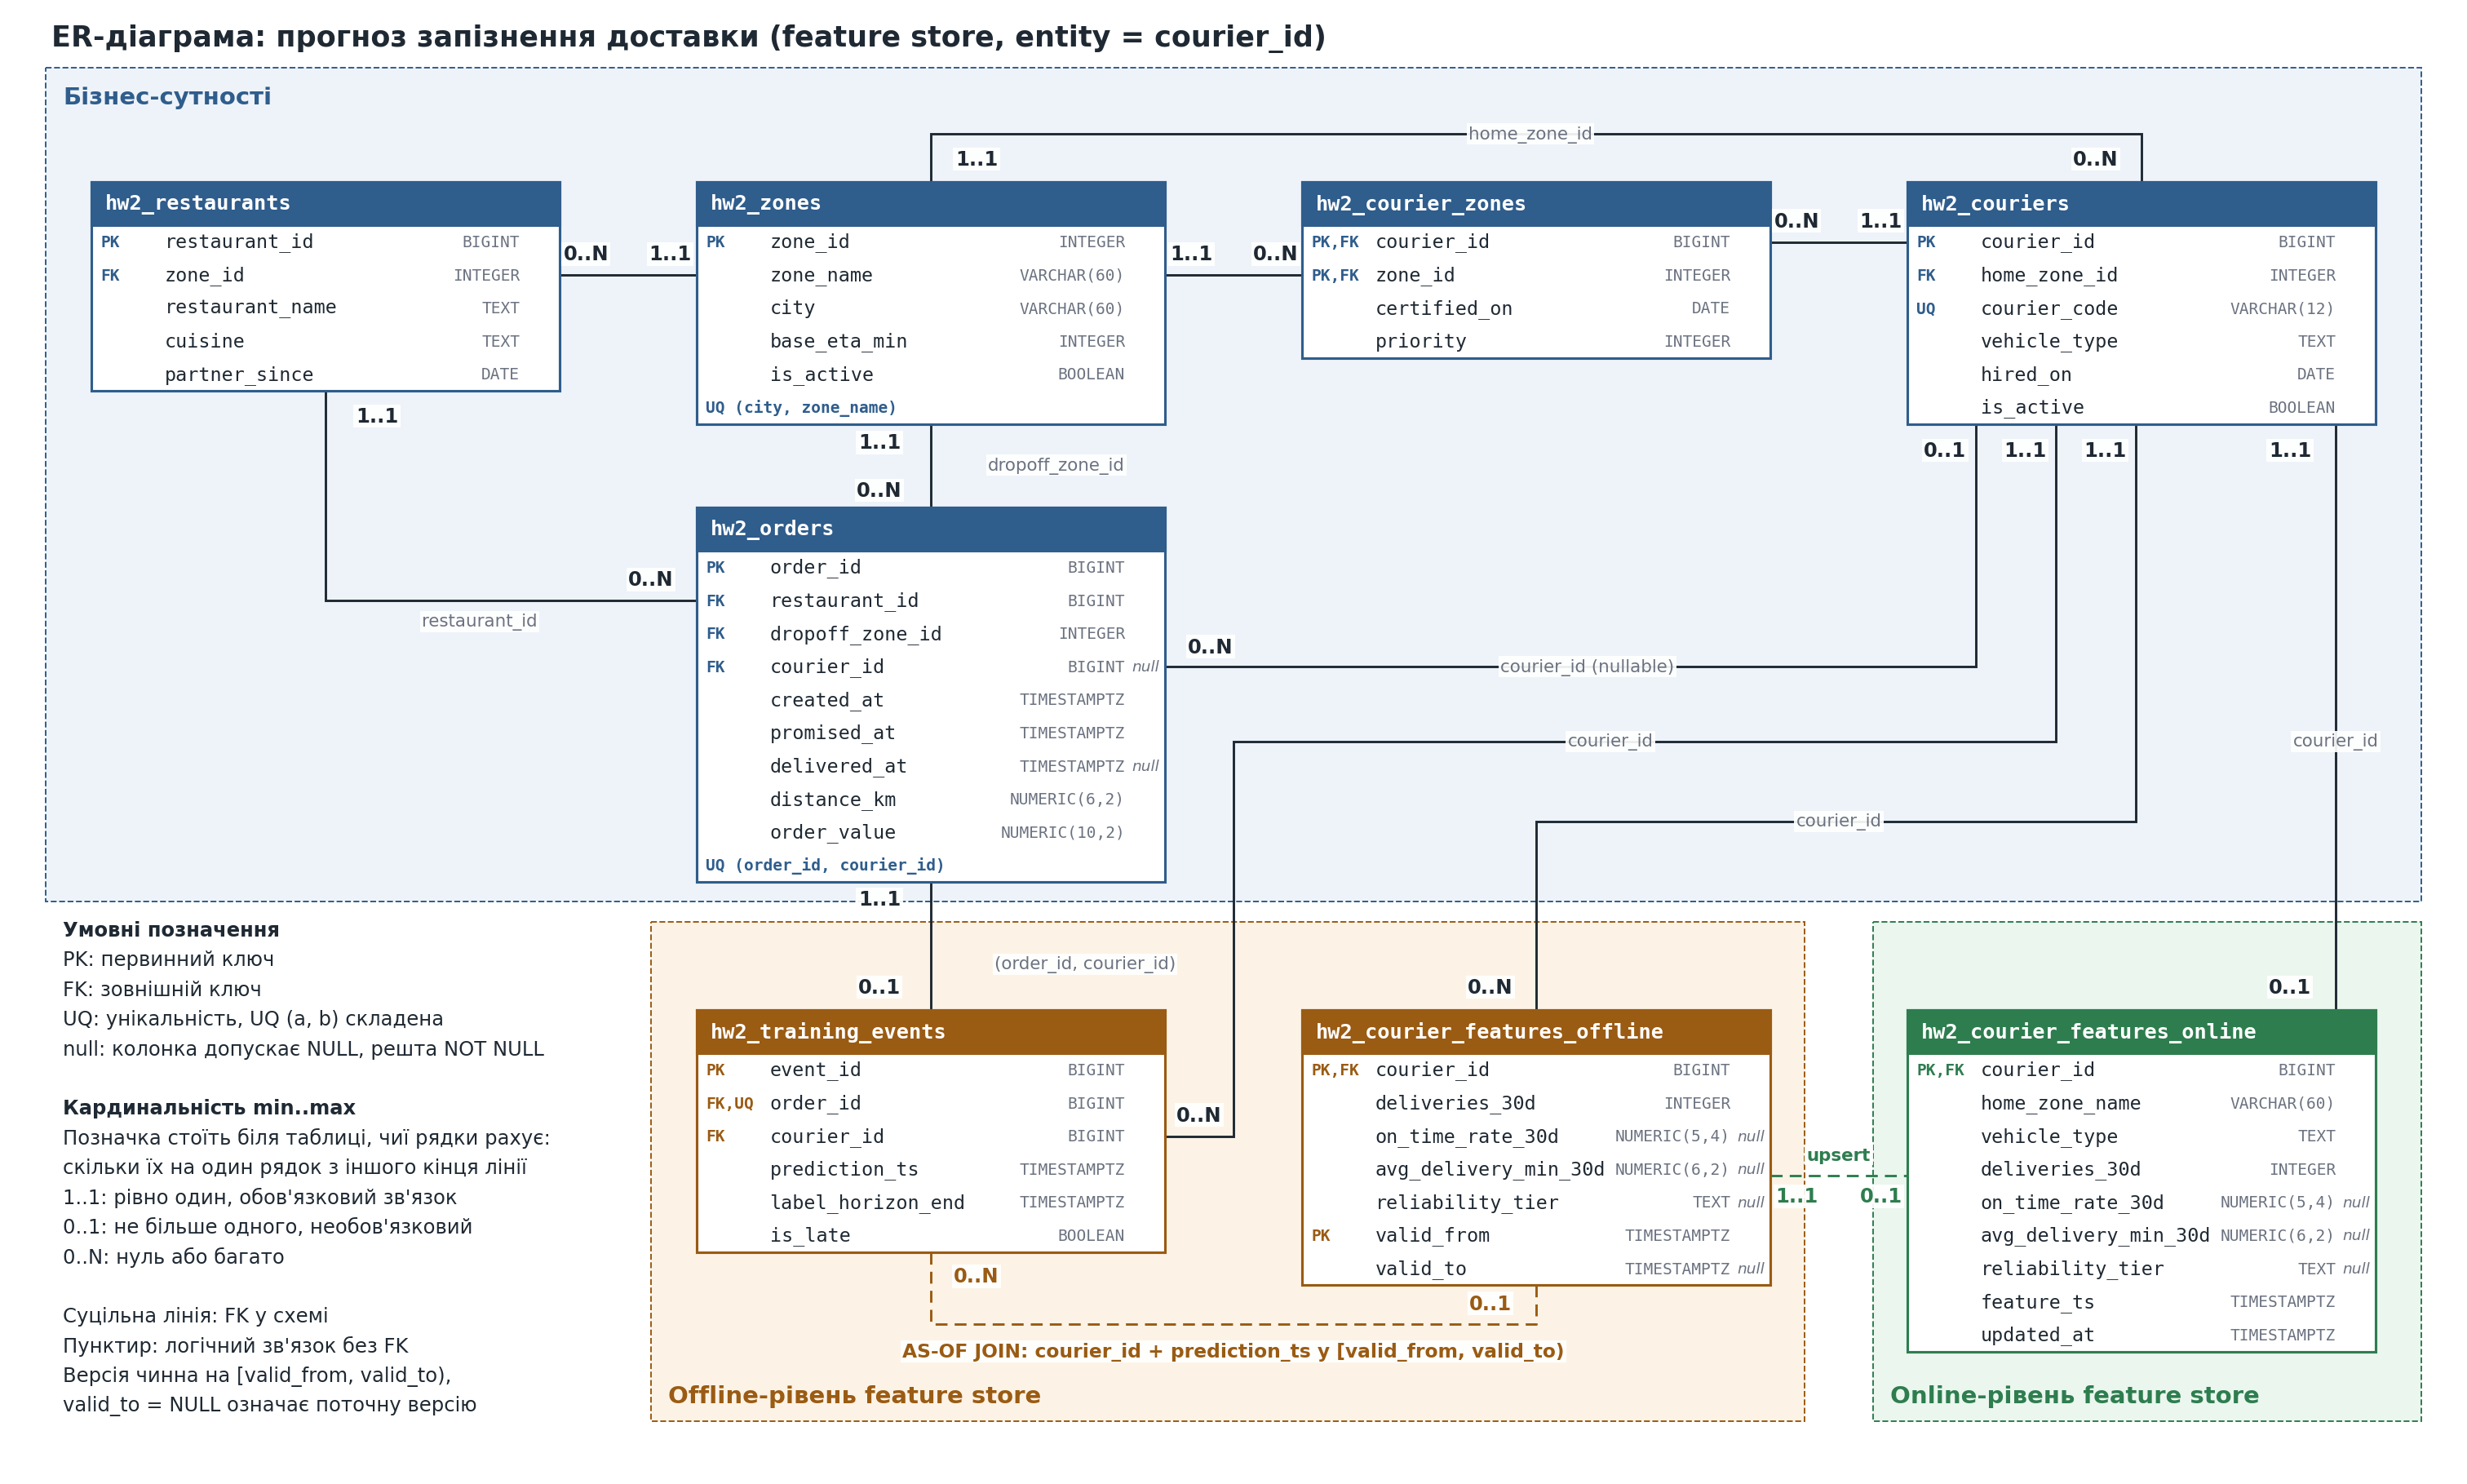

In [5]:
# @title Малювання ER-діаграми: PNG і SVG
LAYERS = {
    'business': ('#2F5D8C', '#EEF3F9', 'Бізнес-сутності'),
    'offline': ('#9A5B13', '#FCF3E6', 'Offline-рівень feature store'),
    'online': ('#2E7D4F', '#EAF6EE', 'Online-рівень feature store'),
}
COL_W, ROW_H, HEAD_H = 4.1, 0.29, 0.38
FIG_W, FIG_H = 21.4, 12.8
INK, MUTED = '#1F2933', '#6B7280'

# Геометрія FK-ліній: точки від child до parent, позиції підписів child і parent,
# підпис колонки (x, y, текст). Значення кардинальностей беруться з ER_REFS.
ER_EDGES = {
    ('hw2_restaurants', 'zone_id'): (
        [(4.8, 2.315), (6.0, 2.315)], (5.03, 2.13), (5.77, 2.13), None),
    ('hw2_couriers', 'home_zone_id'): (
        [(18.65, 1.5), (18.65, 1.08), (8.05, 1.08), (8.05, 1.5)], (18.25, 1.3), (8.45, 1.3),
        (13.3, 1.08, 'home_zone_id')),
    ('hw2_courier_zones', 'courier_id'): (
        [(15.4, 2.025), (16.6, 2.025)], (15.63, 1.84), (16.37, 1.84), None),
    ('hw2_courier_zones', 'zone_id'): (
        [(11.3, 2.315), (10.1, 2.315)], (11.07, 2.13), (10.33, 2.13), None),
    ('hw2_orders', 'restaurant_id'): (
        [(6.0, 5.165), (2.75, 5.165), (2.75, 3.33)], (5.6, 4.98), (3.2, 3.55),
        (4.1, 5.35, 'restaurant_id')),
    ('hw2_orders', 'dropoff_zone_id'): (
        [(8.05, 4.35), (8.05, 3.62)], (7.6, 4.2), (7.6, 3.78),
        (9.15, 3.98, 'dropoff_zone_id')),
    ('hw2_orders', 'courier_id'): (
        [(10.1, 5.745), (17.2, 5.745), (17.2, 3.62)], (10.5, 5.57), (16.93, 3.85),
        (13.8, 5.745, 'courier_id (nullable)')),
    ('hw2_courier_features_offline', 'courier_id'): (
        [(13.35, 8.75), (13.35, 7.1), (18.6, 7.1), (18.6, 3.62)], (12.95, 8.55), (18.33, 3.85),
        (16.0, 7.1, 'courier_id')),
    ('hw2_training_events', 'courier_id'): (
        [(10.1, 9.855), (10.7, 9.855), (10.7, 6.4), (17.9, 6.4), (17.9, 3.62)], (10.4, 9.67), (17.63, 3.85),
        (14.0, 6.4, 'courier_id')),
    ('hw2_training_events', 'order_id'): (
        [(8.05, 8.75), (8.05, 7.63)], (7.6, 8.55), (7.6, 7.78),
        (9.4, 8.35, '(order_id, courier_id)')),
    ('hw2_courier_features_online', 'courier_id'): (
        [(20.35, 8.75), (20.35, 3.62)], (19.95, 8.55), (19.95, 3.85),
        (20.35, 6.4, 'courier_id')),
}


def table_box(spec):
    x, y = spec['pos']
    rows = len(spec['columns']) + len(spec.get('uniques', []))
    return x, y, COL_W, HEAD_H + ROW_H * rows


def on_border(point, spec):
    px, py = point
    x, y, w, h = table_box(spec)
    inside = x - 1e-6 <= px <= x + w + 1e-6 and y - 1e-6 <= py <= y + h + 1e-6
    return inside and min(abs(px - x), abs(px - x - w), abs(py - y), abs(py - y - h)) < 1e-6


def distance(a, b):
    return ((a[0] - b[0]) ** 2 + (a[1] - b[1]) ** 2) ** 0.5


# Лінія починається на child і закінчується на parent, а кожна позначка стоїть біля своєї таблиці.
assert len(ER_EDGES) == len(ER_REFS)
for child, fk, parent, _, _, _, _ in ER_REFS:
    points, child_at, parent_at, _ = ER_EDGES[(child, as_cols(fk)[0])]
    assert on_border(points[0], ER_TABLES[child]) and on_border(points[-1], ER_TABLES[parent])
    assert distance(child_at, points[0]) < distance(child_at, points[-1])
    assert distance(parent_at, points[-1]) < distance(parent_at, points[0])


def draw_table(ax, name, spec):
    x, y, width, height = table_box(spec)
    head_color = LAYERS[spec['layer']][0]
    ax.add_patch(plt.Rectangle((x, y), width, height, fc='white', ec=head_color, lw=1.6, zorder=3))
    ax.add_patch(plt.Rectangle((x, y), width, HEAD_H, fc=head_color, ec=head_color, lw=1.6, zorder=3))
    ax.text(x + 0.12, y + HEAD_H / 2, name, color='white', fontsize=13, fontweight='bold',
            family='DejaVu Sans Mono', va='center', zorder=4)
    for i, (column, data_type, flags) in enumerate(spec['columns']):
        row_y = y + HEAD_H + ROW_H * (i + 0.5)
        marks = [f for f in flags.split(',') if f and f != 'NULL']
        ax.text(x + 0.08, row_y, ','.join(marks), fontsize=10, color=head_color, fontweight='bold',
                family='DejaVu Sans Mono', va='center', zorder=4)
        ax.text(x + 0.64, row_y, column, fontsize=12, color=INK,
                family='DejaVu Sans Mono', va='center', zorder=4)
        ax.text(x + COL_W - 0.35, row_y, data_type, fontsize=10, color=MUTED, ha='right',
                family='DejaVu Sans Mono', va='center', zorder=4)
        if 'NULL' in flags:
            ax.text(x + COL_W - 0.05, row_y, 'null', fontsize=9.5, color=MUTED, ha='right',
                    style='italic', va='center', zorder=4)
    for i, columns in enumerate(spec.get('uniques', [])):
        row_y = y + HEAD_H + ROW_H * (len(spec['columns']) + i + 0.5)
        ax.text(x + 0.08, row_y, f"UQ ({', '.join(columns)})", fontsize=10, color=head_color,
                fontweight='bold', family='DejaVu Sans Mono', va='center', zorder=4)


def edge(ax, points, dashed=False, color=INK):
    xs, ys = zip(*points)
    ax.plot(xs, ys, color=color, lw=1.5, ls=(0, (5, 3)) if dashed else '-', zorder=2,
            solid_joinstyle='miter')


def note(ax, x, y, label, size=12.5, weight='bold', color=INK, ha='center'):
    ax.text(x, y, label, fontsize=size, fontweight=weight, color=color, ha=ha, va='center', zorder=5,
            bbox=dict(fc='white', ec='none', pad=1.2, alpha=0.92))


def draw_er(png_path, svg_path):
    fig = plt.figure(figsize=(FIG_W, FIG_H))
    ax = fig.add_axes([0, 0, 1, 1])
    ax.set_xlim(0, FIG_W)
    ax.set_ylim(FIG_H, 0)
    ax.axis('off')

    ax.text(0.35, 0.24, 'ER-діаграма: прогноз запізнення доставки (feature store, entity = courier_id)',
            fontsize=18, fontweight='bold', color=INK, va='center')

    # Підписи offline- та online-блоків винесено вниз, щоб лінії не перетинали текст.
    for (x, y, w, h, layer, title_at) in [(0.3, 0.5, 20.8, 7.3, 'business', (0.45, 0.76)),
                                          (5.6, 7.98, 10.1, 4.37, 'offline', (5.75, 12.13)),
                                          (16.3, 7.98, 4.8, 4.37, 'online', (16.45, 12.13))]:
        head_color, fill, title = LAYERS[layer]
        ax.add_patch(plt.Rectangle((x, y), w, h, fc=fill, ec=head_color, lw=1, ls='--', zorder=0))
        ax.text(*title_at, title, fontsize=15, fontweight='bold', color=head_color,
                va='center', zorder=1)

    for child, fk, parent, _, child_card, parent_card, _ in ER_REFS:
        points, child_at, parent_at, caption = ER_EDGES[(child, as_cols(fk)[0])]
        edge(ax, points)
        note(ax, *child_at, child_card)
        note(ax, *parent_at, parent_card)
        if caption:
            note(ax, *caption, size=11, weight='normal', color=MUTED)

    # Логічні зв'язки без FK: на одну подію припадає не більше однієї версії, версію читають багато подій.
    edge(ax, [(8.05, 10.87), (8.05, 11.5), (13.35, 11.5), (13.35, 11.16)], dashed=True, color='#9A5B13')
    note(ax, 8.45, 11.08, '0..N', color='#9A5B13')
    note(ax, 12.95, 11.32, '0..1', color='#9A5B13')
    note(ax, 10.7, 11.74, 'AS-OF JOIN: courier_id + prediction_ts у [valid_from, valid_to)',
         size=12, color='#9A5B13')
    edge(ax, [(15.4, 10.2), (16.6, 10.2)], dashed=True, color='#2E7D4F')
    note(ax, 16.0, 10.02, 'upsert', size=11, color='#2E7D4F')
    note(ax, 15.63, 10.38, '1..1', color='#2E7D4F')
    note(ax, 16.37, 10.38, '0..1', color='#2E7D4F')

    for name, spec in ER_TABLES.items():
        draw_table(ax, name, spec)

    legend = [
        ('Умовні позначення', True),
        ('PK: первинний ключ', False),
        ('FK: зовнішній ключ', False),
        ('UQ: унікальність, UQ (a, b) складена', False),
        ('null: колонка допускає NULL, решта NOT NULL', False),
        ('', False),
        ('Кардинальність min..max', True),
        ('Позначка стоїть біля таблиці, чиї рядки рахує:', False),
        ('скільки їх на один рядок з іншого кінця лінії', False),
        ('1..1: рівно один, обов\'язковий зв\'язок', False),
        ('0..1: не більше одного, необов\'язковий', False),
        ('0..N: нуль або багато', False),
        ('', False),
        ('Суцільна лінія: FK у схемі', False),
        ('Пунктир: логічний зв\'язок без FK', False),
        ('Версія чинна на [valid_from, valid_to),', False),
        ('valid_to = NULL означає поточну версію', False),
    ]
    for i, (line, strong) in enumerate(legend):
        ax.text(0.45, 8.05 + i * 0.26, line, fontsize=12.5, color=INK, va='center',
                fontweight='bold' if strong else 'normal')

    fig.savefig(png_path, dpi=140, bbox_inches='tight', facecolor='white')
    fig.savefig(svg_path, bbox_inches='tight', facecolor='white', metadata={'Date': None})
    plt.close(fig)


draw_er('er_diagram.png', 'er_diagram.svg')
display(Image('er_diagram.png'))

In [6]:
# @title Експорт ER-моделі в DBML
def to_dbml():
    lines = ['// ER-модель ДЗ2: прогноз запізнення доставки', '']
    for name, spec in ER_TABLES.items():
        lines.append(f'Table {name} {{')
        pk = [c for c, _, flags in spec['columns'] if 'PK' in flags.split(',')]
        for column, data_type, flags in spec['columns']:
            marks = flags.split(',')
            settings = []
            if len(pk) == 1 and 'PK' in marks:
                settings.append('pk')
            if 'NULL' not in marks and 'PK' not in marks:
                settings.append('not null')
            if 'UQ' in marks:
                settings.append('unique')
            suffix = f" [{', '.join(settings)}]" if settings else ''
            lines.append(f'  {column} {data_type.lower().replace(" ", "")}{suffix}')
        uniques = spec.get('uniques', [])
        if len(pk) > 1 or uniques:
            lines += ['', '  indexes {']
            if len(pk) > 1:
                lines.append(f"    ({', '.join(pk)}) [pk]")
            lines += [f"    ({', '.join(columns)}) [unique]" for columns in uniques]
            lines.append('  }')
        if name == 'hw2_courier_features_offline':
            lines += ['', "  Note: 'Версія чинна на [valid_from, valid_to), valid_to = NULL означає поточну версію'"]
        lines += ['}', '']

    def endpoint(table, columns):
        columns = as_cols(columns)
        return f'{table}.{columns[0]}' if len(columns) == 1 else f"{table}.({', '.join(columns)})"

    for child, fk, parent, pk, child_card, parent_card, _ in ER_REFS:
        relation = '-' if child_card == '0..1' else '>'
        lines.append(f'Ref: {endpoint(child, fk)} {relation} {endpoint(parent, pk)}'
                     f' // child {child_card} : parent {parent_card}')
    lines.append('')

    for layer in LAYERS:
        members = [name for name, spec in ER_TABLES.items() if spec['layer'] == layer]
        lines += [f'TableGroup {layer} {{'] + [f'  {name}' for name in members] + ['}', '']
    return '\n'.join(lines)


dbml = to_dbml()
Path('er_diagram.dbml').write_text(dbml, encoding='utf-8')
print(dbml)

// ER-модель ДЗ2: прогноз запізнення доставки

Table hw2_zones {
  zone_id integer [pk]
  zone_name varchar(60) [not null]
  city varchar(60) [not null]
  base_eta_min integer [not null]
  is_active boolean [not null]

  indexes {
    (city, zone_name) [unique]
  }
}

Table hw2_restaurants {
  restaurant_id bigint [pk]
  zone_id integer [not null]
  restaurant_name text [not null]
  cuisine text [not null]
  partner_since date [not null]
}

Table hw2_couriers {
  courier_id bigint [pk]
  home_zone_id integer [not null]
  courier_code varchar(12) [not null, unique]
  vehicle_type text [not null]
  hired_on date [not null]
  is_active boolean [not null]
}

Table hw2_courier_zones {
  courier_id bigint
  zone_id integer
  certified_on date [not null]
  priority integer [not null]

  indexes {
    (courier_id, zone_id) [pk]
  }
}

Table hw2_orders {
  order_id bigint [pk]
  restaurant_id bigint [not null]
  dropoff_zone_id integer [not null]
  courier_id bigint
  created_at timestamptz [no

## Завдання 2. DDL у PostgreSQL

Три рішення, яких немає у зразку:

- `EXCLUDE USING gist` забороняє перекривання версій на рівні СУБД. Звичайний варіант `courier_id WITH =` потребує розширення `btree_gist`, якого немає в `pgserver`, тому ключ загорнуто в `int8range` і порівнюється вбудованим оператором `&&`.
- Складений FK `(order_id, courier_id)` гарантує, що кур'єр у training event збігається з кур'єром замовлення. PostgreSQL вимагає унікальності цільових колонок FK, тому в `hw2_orders` є `UNIQUE (order_id, courier_id)`. Копія `courier_id` потрібна для AS-OF JOIN без проміжної таблиці.
- У `hw2_courier_features_online` навмисно скопійовано `home_zone_name` і `vehicle_type`, це пояснено в завданні 3.

In [7]:
sql_run("""
CREATE TABLE hw2_zones (
    zone_id      INTEGER PRIMARY KEY,
    zone_name    VARCHAR(60) NOT NULL,
    city         VARCHAR(60) NOT NULL,
    base_eta_min INTEGER NOT NULL
        CHECK (base_eta_min > 0),
    is_active    BOOLEAN NOT NULL DEFAULT TRUE,
    UNIQUE (city, zone_name)
);

CREATE TABLE hw2_restaurants (
    restaurant_id   BIGINT PRIMARY KEY,
    zone_id         INTEGER NOT NULL
        REFERENCES hw2_zones(zone_id),
    restaurant_name TEXT NOT NULL,
    cuisine         TEXT NOT NULL,
    partner_since   DATE NOT NULL
);

CREATE TABLE hw2_couriers (
    courier_id   BIGINT PRIMARY KEY,
    home_zone_id INTEGER NOT NULL
        REFERENCES hw2_zones(zone_id),
    courier_code VARCHAR(12) NOT NULL UNIQUE,
    vehicle_type TEXT NOT NULL
        CHECK (vehicle_type IN ('bike', 'scooter', 'car')),
    hired_on     DATE NOT NULL,
    is_active    BOOLEAN NOT NULL DEFAULT TRUE
);

-- Bridge-таблиця M:N: кур'єр працює в кількох зонах, зону обслуговують кілька кур'єрів.
CREATE TABLE hw2_courier_zones (
    courier_id   BIGINT NOT NULL
        REFERENCES hw2_couriers(courier_id),
    zone_id      INTEGER NOT NULL
        REFERENCES hw2_zones(zone_id),
    certified_on DATE NOT NULL,
    priority     INTEGER NOT NULL
        CHECK (priority BETWEEN 1 AND 3),
    PRIMARY KEY (courier_id, zone_id)
);

CREATE TABLE hw2_orders (
    order_id        BIGINT PRIMARY KEY,
    restaurant_id   BIGINT NOT NULL
        REFERENCES hw2_restaurants(restaurant_id),
    dropoff_zone_id INTEGER NOT NULL
        REFERENCES hw2_zones(zone_id),
    courier_id      BIGINT
        REFERENCES hw2_couriers(courier_id),
    created_at      TIMESTAMPTZ NOT NULL,
    promised_at     TIMESTAMPTZ NOT NULL,
    delivered_at    TIMESTAMPTZ,
    distance_km     NUMERIC(6, 2) NOT NULL
        CHECK (distance_km > 0),
    order_value     NUMERIC(10, 2) NOT NULL
        CHECK (order_value >= 0),
    UNIQUE (order_id, courier_id),
    CHECK (promised_at > created_at),
    CHECK (delivered_at IS NULL OR delivered_at > created_at),
    CHECK (delivered_at IS NULL OR courier_id IS NOT NULL)
);

-- Access pattern: замовлення кур'єра за часом, з них рахуються 30-денні ознаки.
CREATE INDEX hw2_idx_orders_courier_created
    ON hw2_orders (courier_id, created_at DESC);

-- Offline-рівень: історія версій ознак. Версія чинна на [valid_from, valid_to).
CREATE TABLE hw2_courier_features_offline (
    courier_id           BIGINT NOT NULL
        REFERENCES hw2_couriers(courier_id),
    deliveries_30d       INTEGER NOT NULL
        CHECK (deliveries_30d >= 0),
    on_time_rate_30d     NUMERIC(5, 4)
        CHECK (
            on_time_rate_30d IS NULL
            OR on_time_rate_30d BETWEEN 0 AND 1
        ),
    avg_delivery_min_30d NUMERIC(6, 2)
        CHECK (
            avg_delivery_min_30d IS NULL
            OR avg_delivery_min_30d > 0
        ),
    reliability_tier     TEXT
        CHECK (
            reliability_tier IS NULL
            OR reliability_tier IN ('A', 'B', 'C')
        ),
    valid_from           TIMESTAMPTZ NOT NULL,
    valid_to             TIMESTAMPTZ,
    PRIMARY KEY (courier_id, valid_from),
    CHECK (deliveries_30d > 0 OR on_time_rate_30d IS NULL),
    CONSTRAINT hw2_ck_features_valid_range
        CHECK (valid_to IS NULL OR valid_to > valid_from),
    CONSTRAINT hw2_ex_features_no_overlap
        EXCLUDE USING gist (
            int8range(courier_id, courier_id, '[]') WITH &&,
            tstzrange(valid_from, valid_to, '[)') WITH &&
        )
);

-- Основний access pattern: AS-OF пошук версії за courier_id і моментом часу.
CREATE INDEX hw2_idx_courier_features_asof
    ON hw2_courier_features_offline (courier_id, valid_from DESC);

-- Access pattern оновлення online-рівня: лише поточні версії.
CREATE UNIQUE INDEX hw2_uq_courier_features_current
    ON hw2_courier_features_offline (courier_id)
    WHERE valid_to IS NULL;

-- Одна подія на замовлення: момент призначення кур'єра.
CREATE TABLE hw2_training_events (
    event_id          BIGINT
        GENERATED BY DEFAULT AS IDENTITY
        PRIMARY KEY,
    order_id          BIGINT NOT NULL UNIQUE,
    courier_id        BIGINT NOT NULL
        REFERENCES hw2_couriers(courier_id),
    prediction_ts     TIMESTAMPTZ NOT NULL,
    label_horizon_end TIMESTAMPTZ NOT NULL,
    is_late           BOOLEAN NOT NULL,
    CHECK (label_horizon_end > prediction_ts),
    CONSTRAINT hw2_fk_events_order_courier
        FOREIGN KEY (order_id, courier_id)
        REFERENCES hw2_orders(order_id, courier_id)
);

-- Access pattern: події кур'єра за prediction_ts для AS-OF JOIN.
CREATE INDEX hw2_idx_training_events_courier_ts
    ON hw2_training_events (courier_id, prediction_ts);

-- Online-рівень: один денормалізований рядок на кур'єра для lookup за PK.
CREATE TABLE hw2_courier_features_online (
    courier_id           BIGINT PRIMARY KEY
        REFERENCES hw2_couriers(courier_id),
    home_zone_name       VARCHAR(60) NOT NULL,
    vehicle_type         TEXT NOT NULL
        CHECK (vehicle_type IN ('bike', 'scooter', 'car')),
    deliveries_30d       INTEGER NOT NULL
        CHECK (deliveries_30d >= 0),
    on_time_rate_30d     NUMERIC(5, 4)
        CHECK (
            on_time_rate_30d IS NULL
            OR on_time_rate_30d BETWEEN 0 AND 1
        ),
    avg_delivery_min_30d NUMERIC(6, 2)
        CHECK (
            avg_delivery_min_30d IS NULL
            OR avg_delivery_min_30d > 0
        ),
    reliability_tier     TEXT
        CHECK (
            reliability_tier IS NULL
            OR reliability_tier IN ('A', 'B', 'C')
        ),
    feature_ts           TIMESTAMPTZ NOT NULL,
    updated_at           TIMESTAMPTZ NOT NULL
        DEFAULT CURRENT_TIMESTAMP
);
""")

display(sql_df("""
SELECT
    t.relname AS table_name,
    COUNT(*) FILTER (WHERE c.contype = 'p') AS primary_keys,
    COUNT(*) FILTER (WHERE c.contype = 'f') AS foreign_keys,
    COUNT(*) FILTER (WHERE c.contype = 'c') AS checks,
    COUNT(*) FILTER (WHERE c.contype = 'u') AS uniques,
    COUNT(*) FILTER (WHERE c.contype = 'x') AS exclusions
FROM pg_class AS t
LEFT JOIN pg_constraint AS c ON c.conrelid = t.oid
WHERE t.relkind = 'r'
  AND t.relname LIKE 'hw2_%'
GROUP BY t.relname
ORDER BY t.relname
"""))

display(sql_df("""
SELECT tablename, indexname
FROM pg_indexes
WHERE tablename LIKE 'hw2_%'
  AND indexname LIKE 'hw2_%'
ORDER BY tablename, indexname
"""))

,table_name,primary_keys,foreign_keys,checks,uniques,exclusions
0,hw2_courier_features_offline,1,1,6,0,1
1,hw2_courier_features_online,1,1,5,0,0
2,hw2_courier_zones,1,2,1,0,0
3,hw2_couriers,1,1,1,1,0
4,hw2_orders,1,3,5,1,0
5,hw2_restaurants,1,1,0,0,0
6,hw2_training_events,1,2,1,1,0
7,hw2_zones,1,0,1,1,0


,tablename,indexname
0,hw2_courier_features_offline,hw2_courier_features_offline_pkey
1,hw2_courier_features_offline,hw2_ex_features_no_overlap
2,hw2_courier_features_offline,hw2_idx_courier_features_asof
3,hw2_courier_features_offline,hw2_uq_courier_features_current
4,hw2_courier_features_online,hw2_courier_features_online_pkey
5,hw2_courier_zones,hw2_courier_zones_pkey
6,hw2_couriers,hw2_couriers_courier_code_key
7,hw2_couriers,hw2_couriers_pkey
8,hw2_orders,hw2_idx_orders_courier_created
9,hw2_orders,hw2_orders_order_id_courier_id_key


Перевірка відповідності діаграми схемі: кожна колонка, тип, NOT NULL, PK, FK, цільова таблиця FK і UNIQUE з опису ER порівнюються з каталогом PostgreSQL. Кардинальності теж виводяться з каталогу: `1..1` на боці parent вимагає NOT NULL у всіх колонках FK, а `0..1` на боці child вимагає UNIQUE або PK на колонках FK.

In [8]:
# @title Звірка опису ER з каталогом PostgreSQL
TYPE_NAMES = {
    'TIMESTAMPTZ': 'timestamp with time zone',
    'VARCHAR': 'character varying',
}


def catalog_type(er_type):
    base, _, size = er_type.partition('(')
    name = TYPE_NAMES.get(base, base.lower())
    return f'{name}({size}' if size else name


db_columns = sql_df("""
SELECT
    c.relname AS table_name,
    a.attname AS column_name,
    format_type(a.atttypid, a.atttypmod) AS data_type,
    a.attnotnull AS not_null
FROM pg_attribute AS a
JOIN pg_class AS c ON c.oid = a.attrelid
WHERE c.relkind = 'r'
  AND c.relname LIKE 'hw2_%'
  AND a.attnum > 0
  AND NOT a.attisdropped
""")

db_keys = sql_df("""
SELECT
    c.conrelid::regclass::text AS table_name,
    c.contype::text AS key_type,
    a.attname AS column_name
FROM pg_constraint AS c
CROSS JOIN LATERAL unnest(c.conkey) AS k(attnum)
JOIN pg_attribute AS a
  ON a.attrelid = c.conrelid
 AND a.attnum = k.attnum
WHERE c.contype IN ('p', 'f')
  AND c.conrelid::regclass::text LIKE 'hw2_%'
""")

er_columns = {
    (table, column, catalog_type(data_type), 'NULL' not in flags.split(','))
    for table, spec in ER_TABLES.items()
    for column, data_type, flags in spec['columns']
}
er_keys = {
    (table, key_type, column)
    for table, spec in ER_TABLES.items()
    for column, _, flags in spec['columns']
    for key_type, mark in (('p', 'PK'), ('f', 'FK'))
    if mark in flags.split(',')
}

db_constraints = sql_df("""
SELECT
    c.conrelid::regclass::text AS table_name,
    c.contype::text AS key_type,
    ARRAY(
        SELECT a.attname::text
        FROM unnest(c.conkey) WITH ORDINALITY AS k(attnum, ord)
        JOIN pg_attribute AS a
          ON a.attrelid = c.conrelid
         AND a.attnum = k.attnum
        ORDER BY k.ord
    ) AS columns,
    c.confrelid::regclass::text AS parent_table,
    ARRAY(
        SELECT a.attname::text
        FROM unnest(c.confkey) WITH ORDINALITY AS k(attnum, ord)
        JOIN pg_attribute AS a
          ON a.attrelid = c.confrelid
         AND a.attnum = k.attnum
        ORDER BY k.ord
    ) AS parent_columns
FROM pg_constraint AS c
WHERE c.contype IN ('p', 'f', 'u')
  AND c.conrelid::regclass::text LIKE 'hw2_%'
""")

catalog_columns = set(db_columns.itertuples(index=False, name=None))
catalog_keys = set(db_keys.itertuples(index=False, name=None))

constraint_rows = list(db_constraints.itertuples(index=False))
catalog_refs = {
    (r.table_name, tuple(r.columns), r.parent_table, tuple(r.parent_columns))
    for r in constraint_rows if r.key_type == 'f'
}
catalog_uniques = {(r.table_name, tuple(r.columns)) for r in constraint_rows if r.key_type == 'u'}
unique_keys = {
    (r.table_name, frozenset(r.columns)) for r in constraint_rows if r.key_type in ('p', 'u')
}

er_refs = {(child, as_cols(fk), parent, as_cols(pk)) for child, fk, parent, pk, *_ in ER_REFS}
er_uniques = {
    (table, (column,))
    for table, spec in ER_TABLES.items()
    for column, _, flags in spec['columns']
    if 'UQ' in flags.split(',')
} | {
    (table, columns)
    for table, spec in ER_TABLES.items()
    for columns in spec.get('uniques', [])
}

assert er_columns == catalog_columns, er_columns ^ catalog_columns
assert er_keys == catalog_keys, er_keys ^ catalog_keys
assert er_refs == catalog_refs, er_refs ^ catalog_refs
assert er_uniques == catalog_uniques, er_uniques ^ catalog_uniques

not_null = {(table, column) for table, column, _, required in catalog_columns if required}
for child, fk, parent, _, child_card, parent_card, _ in ER_REFS:
    fk_columns = set(as_cols(fk))
    expected_parent = '1..1' if all((child, c) in not_null for c in fk_columns) else '0..1'
    fk_is_unique = any(table == child and key <= fk_columns for table, key in unique_keys)
    expected_child = '0..1' if fk_is_unique else '0..N'
    assert (child_card, parent_card) == (expected_child, expected_parent), (child, fk)

print(f'ER = DDL: таблиць {len(ER_TABLES)}, колонок {len(catalog_columns)}, '
      f'елементів PK/FK {len(catalog_keys)}, FK-зв\'язків {len(catalog_refs)}, '
      f'UNIQUE {len(catalog_uniques)}')

ER = DDL: таблиць 8, колонок 51, елементів PK/FK 21, FK-зв'язків 11, UNIQUE 4


### Тестові дані

Усі часові значення мають явний UTC-зсув `+00`. Сценарні деталі, на які спираються перевірки далі:

- кур'єр 101 має 4 послідовні версії, усього в історії 12 рядків для 4 кур'єрів;
- кур'єр 104 отримав перше замовлення до публікації першої версії (холодний старт);
- подія замовлення 1003 припадає точно на межу версій;
- кур'єр 105 не має ані ознак, ані подій;
- замовлення 1014 скасоване без кур'єра, тому training event для нього немає.

In [9]:
sql_run("""
INSERT INTO hw2_zones
    (zone_id, zone_name, city, base_eta_min, is_active)
VALUES
    (1, 'Podil',    'Kyiv', 30, TRUE),
    (2, 'Pechersk', 'Kyiv', 35, TRUE),
    (3, 'Obolon',   'Kyiv', 32, TRUE),
    (4, 'Rynok',    'Lviv', 28, TRUE),
    (5, 'Teremky',  'Kyiv', 45, FALSE);

INSERT INTO hw2_restaurants
    (restaurant_id, zone_id, restaurant_name, cuisine, partner_since)
VALUES
    (11, 1, 'Varenyky House', 'ukrainian', DATE '2025-03-01'),
    (12, 2, 'Sushi Point',    'japanese',  DATE '2025-06-15'),
    (13, 3, 'Burger Yard',    'american',  DATE '2024-11-20'),
    (14, 1, 'Pizza Forno',    'italian',   DATE '2026-01-12');

INSERT INTO hw2_couriers
    (courier_id, home_zone_id, courier_code, vehicle_type, hired_on, is_active)
VALUES
    (101, 1, 'C-0101', 'bike',    DATE '2026-02-10', TRUE),
    (102, 2, 'C-0102', 'scooter', DATE '2026-03-15', TRUE),
    (103, 3, 'C-0103', 'car',     DATE '2025-11-01', TRUE),
    (104, 1, 'C-0104', 'bike',    DATE '2026-09-18', TRUE),
    (105, 3, 'C-0105', 'scooter', DATE '2026-08-01', FALSE);

INSERT INTO hw2_courier_zones
    (courier_id, zone_id, certified_on, priority)
VALUES
    (101, 1, DATE '2026-02-10', 1),
    (101, 2, DATE '2026-05-04', 2),
    (102, 2, DATE '2026-03-15', 1),
    (102, 1, DATE '2026-06-01', 2),
    (103, 3, DATE '2025-11-01', 1),
    (103, 2, DATE '2026-04-20', 2),
    (104, 1, DATE '2026-09-18', 1),
    (105, 3, DATE '2026-08-01', 1);

INSERT INTO hw2_orders
    (order_id, restaurant_id, dropoff_zone_id, courier_id,
     created_at, promised_at, delivered_at, distance_km, order_value)
VALUES
    (1001, 11, 1, 101, TIMESTAMPTZ '2026-09-05 11:55:00+00', TIMESTAMPTZ '2026-09-05 12:35:00+00', TIMESTAMPTZ '2026-09-05 12:28:00+00', 3.20, 420.00),
    (1002, 14, 2, 101, TIMESTAMPTZ '2026-09-11 17:55:00+00', TIMESTAMPTZ '2026-09-11 18:35:00+00', TIMESTAMPTZ '2026-09-11 18:49:00+00', 4.10, 515.50),
    (1003, 11, 1, 101, TIMESTAMPTZ '2026-09-15 05:55:00+00', TIMESTAMPTZ '2026-09-15 06:35:00+00', TIMESTAMPTZ '2026-09-15 06:44:00+00', 2.80, 260.00),
    (1004, 14, 1, 101, TIMESTAMPTZ '2026-09-19 12:25:00+00', TIMESTAMPTZ '2026-09-19 13:05:00+00', TIMESTAMPTZ '2026-09-19 13:21:00+00', 3.60, 610.00),
    (1005, 11, 2, 101, TIMESTAMPTZ '2026-09-24 18:10:00+00', TIMESTAMPTZ '2026-09-24 18:50:00+00', TIMESTAMPTZ '2026-09-24 19:12:00+00', 4.50, 380.00),
    (1006, 12, 2, 102, TIMESTAMPTZ '2026-09-05 13:15:00+00', TIMESTAMPTZ '2026-09-05 13:55:00+00', TIMESTAMPTZ '2026-09-05 13:47:00+00', 2.40, 890.00),
    (1007, 12, 1, 102, TIMESTAMPTZ '2026-09-20 19:05:00+00', TIMESTAMPTZ '2026-09-20 19:45:00+00', TIMESTAMPTZ '2026-09-20 19:38:00+00', 3.90, 745.00),
    (1008, 14, 2, 102, TIMESTAMPTZ '2026-10-02 11:40:00+00', TIMESTAMPTZ '2026-10-02 12:20:00+00', TIMESTAMPTZ '2026-10-02 12:09:00+00', 3.10, 320.00),
    (1009, 13, 3, 103, TIMESTAMPTZ '2026-09-10 20:00:00+00', TIMESTAMPTZ '2026-09-10 20:40:00+00', TIMESTAMPTZ '2026-09-10 20:31:00+00', 5.20, 470.00),
    (1010, 13, 2, 103, TIMESTAMPTZ '2026-09-25 20:30:00+00', TIMESTAMPTZ '2026-09-25 21:10:00+00', TIMESTAMPTZ '2026-09-25 21:26:00+00', 6.30, 555.00),
    (1011, 13, 3, 103, TIMESTAMPTZ '2026-10-03 13:00:00+00', TIMESTAMPTZ '2026-10-03 13:40:00+00', TIMESTAMPTZ '2026-10-03 13:52:00+00', 4.80, 410.00),
    (1012, 11, 1, 104, TIMESTAMPTZ '2026-09-19 12:10:00+00', TIMESTAMPTZ '2026-09-19 12:50:00+00', TIMESTAMPTZ '2026-09-19 13:03:00+00', 2.90, 300.00),
    (1013, 14, 1, 104, TIMESTAMPTZ '2026-09-28 17:20:00+00', TIMESTAMPTZ '2026-09-28 18:00:00+00', TIMESTAMPTZ '2026-09-28 18:17:00+00', 3.30, 640.00),
    (1014, 12, 2, NULL, TIMESTAMPTZ '2026-09-22 10:00:00+00', TIMESTAMPTZ '2026-09-22 10:40:00+00', NULL, 2.60, 510.00);

INSERT INTO hw2_courier_features_offline
    (courier_id, deliveries_30d, on_time_rate_30d, avg_delivery_min_30d,
     reliability_tier, valid_from, valid_to)
VALUES
    (101,  96, 0.9400, 28.40, 'A', TIMESTAMPTZ '2026-09-01 06:00:00+00', TIMESTAMPTZ '2026-09-08 06:00:00+00'),
    (101, 104, 0.9100, 29.80, 'A', TIMESTAMPTZ '2026-09-08 06:00:00+00', TIMESTAMPTZ '2026-09-15 06:00:00+00'),
    (101,  99, 0.8200, 33.10, 'B', TIMESTAMPTZ '2026-09-15 06:00:00+00', TIMESTAMPTZ '2026-09-22 06:00:00+00'),
    (101,  88, 0.7600, 36.50, 'C', TIMESTAMPTZ '2026-09-22 06:00:00+00', NULL),
    (102,  70, 0.8400, 35.00, 'C', TIMESTAMPTZ '2026-09-01 06:00:00+00', TIMESTAMPTZ '2026-09-15 06:00:00+00'),
    (102,  75, 0.8700, 31.00, 'B', TIMESTAMPTZ '2026-09-15 06:00:00+00', TIMESTAMPTZ '2026-09-29 06:00:00+00'),
    (102,  81, 0.9300, 27.60, 'A', TIMESTAMPTZ '2026-09-29 06:00:00+00', NULL),
    (103, 120, 0.9600, 24.20, 'A', TIMESTAMPTZ '2026-09-03 06:00:00+00', TIMESTAMPTZ '2026-09-17 06:00:00+00'),
    (103, 115, 0.9000, 26.70, 'B', TIMESTAMPTZ '2026-09-17 06:00:00+00', TIMESTAMPTZ '2026-10-01 06:00:00+00'),
    (103, 109, 0.8400, 30.90, 'B', TIMESTAMPTZ '2026-10-01 06:00:00+00', NULL),
    (104,   1, 0.0000, 53.00, NULL, TIMESTAMPTZ '2026-09-20 06:00:00+00', TIMESTAMPTZ '2026-09-27 06:00:00+00'),
    (104,  12, 0.7500, 37.20, 'C', TIMESTAMPTZ '2026-09-27 06:00:00+00', NULL);

INSERT INTO hw2_training_events
    (order_id, courier_id, prediction_ts, label_horizon_end, is_late)
VALUES
    (1001, 101, TIMESTAMPTZ '2026-09-05 12:00:00+00', TIMESTAMPTZ '2026-09-05 12:35:00+00', FALSE),
    (1002, 101, TIMESTAMPTZ '2026-09-11 18:00:00+00', TIMESTAMPTZ '2026-09-11 18:35:00+00', TRUE),
    (1003, 101, TIMESTAMPTZ '2026-09-15 06:00:00+00', TIMESTAMPTZ '2026-09-15 06:35:00+00', TRUE),
    (1004, 101, TIMESTAMPTZ '2026-09-19 12:30:00+00', TIMESTAMPTZ '2026-09-19 13:05:00+00', TRUE),
    (1005, 101, TIMESTAMPTZ '2026-09-24 18:15:00+00', TIMESTAMPTZ '2026-09-24 18:50:00+00', TRUE),
    (1006, 102, TIMESTAMPTZ '2026-09-05 13:20:00+00', TIMESTAMPTZ '2026-09-05 13:55:00+00', FALSE),
    (1007, 102, TIMESTAMPTZ '2026-09-20 19:10:00+00', TIMESTAMPTZ '2026-09-20 19:45:00+00', FALSE),
    (1008, 102, TIMESTAMPTZ '2026-10-02 11:45:00+00', TIMESTAMPTZ '2026-10-02 12:20:00+00', FALSE),
    (1009, 103, TIMESTAMPTZ '2026-09-10 20:05:00+00', TIMESTAMPTZ '2026-09-10 20:40:00+00', FALSE),
    (1010, 103, TIMESTAMPTZ '2026-09-25 20:35:00+00', TIMESTAMPTZ '2026-09-25 21:10:00+00', TRUE),
    (1011, 103, TIMESTAMPTZ '2026-10-03 13:05:00+00', TIMESTAMPTZ '2026-10-03 13:40:00+00', TRUE),
    (1012, 104, TIMESTAMPTZ '2026-09-19 12:15:00+00', TIMESTAMPTZ '2026-09-19 12:50:00+00', TRUE),
    (1013, 104, TIMESTAMPTZ '2026-09-28 17:25:00+00', TIMESTAMPTZ '2026-09-28 18:00:00+00', TRUE);
""")

row_counts = sql_df("""
SELECT 'hw2_zones' AS table_name, COUNT(*) AS rows_n FROM hw2_zones
UNION ALL SELECT 'hw2_restaurants', COUNT(*) FROM hw2_restaurants
UNION ALL SELECT 'hw2_couriers', COUNT(*) FROM hw2_couriers
UNION ALL SELECT 'hw2_courier_zones', COUNT(*) FROM hw2_courier_zones
UNION ALL SELECT 'hw2_orders', COUNT(*) FROM hw2_orders
UNION ALL SELECT 'hw2_courier_features_offline', COUNT(*) FROM hw2_courier_features_offline
UNION ALL SELECT 'hw2_training_events', COUNT(*) FROM hw2_training_events
""")
display(row_counts)

display(sql_df("""
SELECT
    courier_id,
    COUNT(*) AS versions_n,
    MIN(valid_from) AS first_valid_from,
    COUNT(*) FILTER (WHERE valid_to IS NULL) AS open_versions_n
FROM hw2_courier_features_offline
GROUP BY courier_id
ORDER BY courier_id
"""))

,table_name,rows_n
0,hw2_zones,5
1,hw2_restaurants,4
2,hw2_couriers,5
3,hw2_courier_zones,8
4,hw2_orders,14
5,hw2_courier_features_offline,12
6,hw2_training_events,13


,courier_id,versions_n,first_valid_from,open_versions_n
0,101,4,2026-09-01 06:00:00+00:00,1
1,102,3,2026-09-01 06:00:00+00:00,1
2,103,3,2026-09-03 06:00:00+00:00,1
3,104,2,2026-09-20 06:00:00+00:00,1


Перевірка узгодженості подій із замовленнями. Міжтабличні правила не можна виразити через `CHECK`, тому вони перевіряються запитом. Кожне правило має дати 0 порушень.

In [10]:
event_checks = sql_df("""
SELECT
    COUNT(*) FILTER (WHERE e.prediction_ts < o.created_at)
        AS prediction_before_order,
    COUNT(*) FILTER (WHERE e.is_late IS DISTINCT FROM (o.delivered_at > o.promised_at))
        AS label_differs_from_order,
    COUNT(*) FILTER (WHERE e.label_horizon_end <> o.promised_at)
        AS horizon_differs_from_promise,
    COUNT(*) FILTER (WHERE e.prediction_ts >= e.label_horizon_end)
        AS prediction_after_horizon
FROM hw2_training_events AS e
JOIN hw2_orders AS o ON o.order_id = e.order_id
""")
display(event_checks)
assert event_checks.iloc[0].sum() == 0

,prediction_before_order,label_differs_from_order,horizon_differs_from_promise,prediction_after_horizon
0,0,0,0,0


### Заповнення online-рівня

Online-таблиця наповнюється лише з поточних версій offline-рівня. Той самий запит використовується і для першого завантаження, і для регулярного оновлення: `ON CONFLICT` робить його ідемпотентним, а умова на `feature_ts` не дає старішому запуску перезаписати новіші значення.

In [11]:
REFRESH_ONLINE_SQL = """
INSERT INTO hw2_courier_features_online AS t
    (courier_id, home_zone_name, vehicle_type, deliveries_30d, on_time_rate_30d,
     avg_delivery_min_30d, reliability_tier, feature_ts, updated_at)
SELECT
    f.courier_id,
    z.zone_name,
    c.vehicle_type,
    f.deliveries_30d,
    f.on_time_rate_30d,
    f.avg_delivery_min_30d,
    f.reliability_tier,
    f.valid_from,
    CURRENT_TIMESTAMP
FROM hw2_courier_features_offline AS f
JOIN hw2_couriers AS c ON c.courier_id = f.courier_id
JOIN hw2_zones AS z ON z.zone_id = c.home_zone_id
WHERE f.valid_to IS NULL
ON CONFLICT (courier_id) DO UPDATE
SET home_zone_name       = EXCLUDED.home_zone_name,
    vehicle_type         = EXCLUDED.vehicle_type,
    deliveries_30d       = EXCLUDED.deliveries_30d,
    on_time_rate_30d     = EXCLUDED.on_time_rate_30d,
    avg_delivery_min_30d = EXCLUDED.avg_delivery_min_30d,
    reliability_tier     = EXCLUDED.reliability_tier,
    feature_ts           = EXCLUDED.feature_ts,
    updated_at           = EXCLUDED.updated_at
WHERE EXCLUDED.feature_ts >= t.feature_ts
"""

ONLINE_DRIFT_SQL = """
SELECT COUNT(*) AS drifted_rows
FROM hw2_courier_features_online AS o
JOIN hw2_courier_features_offline AS f
  ON f.courier_id = o.courier_id
 AND f.valid_to IS NULL
JOIN hw2_couriers AS c ON c.courier_id = o.courier_id
JOIN hw2_zones AS z ON z.zone_id = c.home_zone_id
WHERE o.feature_ts <> f.valid_from
   OR o.deliveries_30d <> f.deliveries_30d
   OR o.on_time_rate_30d IS DISTINCT FROM f.on_time_rate_30d
   OR o.avg_delivery_min_30d IS DISTINCT FROM f.avg_delivery_min_30d
   OR o.reliability_tier IS DISTINCT FROM f.reliability_tier
   OR o.vehicle_type <> c.vehicle_type
   OR o.home_zone_name <> z.zone_name
"""

sql_run(REFRESH_ONLINE_SQL)
sql_run(REFRESH_ONLINE_SQL)

online_rows = sql_df("""
SELECT
    courier_id, home_zone_name, vehicle_type, deliveries_30d,
    on_time_rate_30d, avg_delivery_min_30d, reliability_tier, feature_ts
FROM hw2_courier_features_online
ORDER BY courier_id
""")
display(online_rows)

online_drift = sql_df(ONLINE_DRIFT_SQL)
display(online_drift)
assert len(online_rows) == 4
assert online_drift.loc[0, 'drifted_rows'] == 0

,courier_id,home_zone_name,vehicle_type,deliveries_30d,on_time_rate_30d,avg_delivery_min_30d,reliability_tier,feature_ts
0,101,Podil,bike,88,0.76,36.5,C,2026-09-22 06:00:00+00:00
1,102,Pechersk,scooter,81,0.93,27.6,A,2026-09-29 06:00:00+00:00
2,103,Obolon,car,109,0.84,30.9,B,2026-10-01 06:00:00+00:00
3,104,Podil,bike,12,0.75,37.2,C,2026-09-27 06:00:00+00:00


,drifted_rows
0,0


### Перевірка обмежень

Кожен запис нижче навмисно порушує правило. Усі команди мають завершитися помилкою, а транзакція відкочується, тому дані не змінюються.

In [12]:
BAD_STATEMENTS = {
    'valid_to = valid_from': """
        INSERT INTO hw2_courier_features_offline (courier_id, deliveries_30d, valid_from, valid_to)
        VALUES (105, 0, TIMESTAMPTZ '2026-09-01 06:00:00+00', TIMESTAMPTZ '2026-09-01 06:00:00+00')
    """,
    'valid_to < valid_from': """
        INSERT INTO hw2_courier_features_offline (courier_id, deliveries_30d, valid_from, valid_to)
        VALUES (105, 0, TIMESTAMPTZ '2026-09-02 06:00:00+00', TIMESTAMPTZ '2026-09-01 06:00:00+00')
    """,
    'перекривання версій': """
        INSERT INTO hw2_courier_features_offline (courier_id, deliveries_30d, valid_from, valid_to)
        VALUES (101, 90, TIMESTAMPTZ '2026-09-10 06:00:00+00', TIMESTAMPTZ '2026-09-12 06:00:00+00')
    """,
    'частка поза [0, 1]': """
        INSERT INTO hw2_courier_features_offline (courier_id, deliveries_30d, on_time_rate_30d, valid_from)
        VALUES (105, 5, 1.5000, TIMESTAMPTZ '2026-09-01 06:00:00+00')
    """,
    'кур\'єр не збігається з замовленням': """
        INSERT INTO hw2_training_events (order_id, courier_id, prediction_ts, label_horizon_end, is_late)
        VALUES (1014, 101, TIMESTAMPTZ '2026-09-22 10:05:00+00', TIMESTAMPTZ '2026-09-22 10:40:00+00', FALSE)
    """,
    'горизонт не пізніше прогнозу': """
        UPDATE hw2_training_events
        SET label_horizon_end = prediction_ts
        WHERE order_id = 1001
    """,
    'невідомий тип транспорту': """
        UPDATE hw2_couriers SET vehicle_type = 'drone' WHERE courier_id = 101
    """,
}

constraint_tests = []
for case, statement in BAD_STATEMENTS.items():
    try:
        with engine.begin() as conn:
            conn.execute(text(statement))
        constraint_tests.append((case, 'ACCEPTED', None))
    except IntegrityError as error:
        constraint_tests.append((case, type(error.orig).__name__, error.orig.diag.constraint_name))

constraint_tests = pd.DataFrame(constraint_tests, columns=['case', 'error', 'constraint'])
display(constraint_tests)
assert not (constraint_tests['error'] == 'ACCEPTED').any()

,case,error,constraint
0,valid_to = valid_from,CheckViolation,hw2_ck_features_valid_range
1,valid_to < valid_from,CheckViolation,hw2_ck_features_valid_range
2,перекривання версій,ExclusionViolation,hw2_ex_features_no_overlap
3,"частка поза [0, 1]",CheckViolation,hw2_courier_features_offline_on_time_rate_30d_check
4,кур'єр не збігається з замовленням,ForeignKeyViolation,hw2_fk_events_order_courier
5,горизонт не пізніше прогнозу,CheckViolation,hw2_training_events_check
6,невідомий тип транспорту,CheckViolation,hw2_couriers_vehicle_type_check


## Завдання 3. Нормалізація

Сім таблиць бізнес- та offline-рівня перебувають у 3НФ. 1НФ: значення атомарні, зони кур'єра винесено в bridge-таблицю. 2НФ: складений первинний ключ мають лише `hw2_courier_zones` і offline-таблиця, неключові атрибути залежать від усього ключа. 3НФ: немає транзитивних залежностей неключових атрибутів від ключа.

Функціональні залежності:

- `hw2_zones`: `zone_id → zone_name, city, base_eta_min, is_active`, `(city, zone_name)` теж ключ;
- `hw2_restaurants`: `restaurant_id → zone_id, restaurant_name, cuisine, partner_since`;
- `hw2_couriers`: `courier_id → home_zone_id, courier_code, vehicle_type, hired_on, is_active`, `courier_code` теж ключ;
- `hw2_courier_zones`: `(courier_id, zone_id) → certified_on, priority`;
- `hw2_orders`: `order_id →` усі інші колонки;
- offline: `(courier_id, valid_from) →` усі ознаки, `valid_to`;
- `hw2_training_events`: `event_id →` усі інші колонки, `order_id` теж ключ.

Назву зони винесено в `hw2_zones`, щоб прибрати транзитивну залежність `courier_id → home_zone_id → zone_name`. `reliability_tier` не є функцією `on_time_rate_30d`: рівень виставляє операційна команда, частка 0.84 має C у кур'єра 102 і B у кур'єра 103. Копію `courier_id` у подіях тримає узгодженою складений FK.

`hw2_courier_features_online` денормалізована навмисно. Усередині таблиці все залежить від `courier_id`, надлишковість є між таблицями: рядок копіює поточну offline-версію, `vehicle_type` і `home_zone_name`, а назва зони повторюється (Podil у 101 і 104). Кожне призначення читає один рядок за `courier_id`: низька latency без AS-OF пошуку й двох JOIN (`hw2_couriers`, `hw2_zones`).

Ризик: копія розходиться з джерелом після зміни зони, транспорту або запізнілого завантаження ознак, і прогноз отримує застарілі значення.

Пакетна задача в одній транзакції закриває поточну offline-версію, додає нову й виконує upsert за `courier_id`. Розбіжності виявляє `ONLINE_DRIFT_SQL`, свіжість контролює `feature_ts`.

## Завдання 4. Point-in-Time correctness

Історія містить 12 версій для 4 кур'єрів, кур'єр 101 має 4 послідовні версії. Спершу перевірка перекривання: запит з умови завдання з адаптованими назвами.

In [13]:
OVERLAP_CHECK_SQL = """
SELECT
    a.courier_id,
    a.valid_from AS a_from,
    a.valid_to   AS a_to,
    b.valid_from AS b_from,
    b.valid_to   AS b_to
FROM {table} AS a
JOIN {table} AS b
  ON a.courier_id = b.courier_id
 AND a.valid_from < COALESCE(b.valid_to, 'infinity'::timestamptz)
 AND b.valid_from < COALESCE(a.valid_to, 'infinity'::timestamptz)
 AND a.valid_from < b.valid_from
"""

overlaps = sql_df(OVERLAP_CHECK_SQL.format(table='hw2_courier_features_offline'))
print('overlapping pairs:', len(overlaps))
display(overlaps)
assert overlaps.empty

invalid_ranges = sql_df("""
SELECT COUNT(*) AS invalid_ranges
FROM hw2_courier_features_offline
WHERE valid_to IS NOT NULL
  AND valid_to <= valid_from
""")
display(invalid_ranges)
assert invalid_ranges.loc[0, 'invalid_ranges'] == 0

overlapping pairs: 0


,courier_id,a_from,a_to,b_from,b_to


,invalid_ranges
0,0


Порожній результат має сенс, лише якщо запит здатен знайти перекривання. Нижче він виконується на тимчасовій копії без `EXCLUDE`, куди додано одну конфліктну версію, і повертає цю пару. Транзакція відкочується. Запит порівнює лише пари з різним `valid_from`, а збіг `valid_from` виключає первинний ключ.

In [14]:
with engine.connect() as conn:
    trans = conn.begin()
    conn.execute(text("""
        CREATE TEMP TABLE hw2_tmp_features_no_exclude ON COMMIT DROP AS
        SELECT * FROM hw2_courier_features_offline
    """))
    conn.execute(text("""
        INSERT INTO hw2_tmp_features_no_exclude (courier_id, deliveries_30d, valid_from, valid_to)
        VALUES (101, 90, TIMESTAMPTZ '2026-09-10 06:00:00+00', TIMESTAMPTZ '2026-09-12 06:00:00+00')
    """))
    detected = fetch(conn, OVERLAP_CHECK_SQL.format(table='hw2_tmp_features_no_exclude'))
    trans.rollback()

display(detected)
assert len(detected) == 1

,courier_id,a_from,a_to,b_from,b_to
0,101,2026-09-08 06:00:00+00:00,2026-09-15 06:00:00+00:00,2026-09-10 06:00:00+00:00,2026-09-12 06:00:00+00:00


### AS-OF SELECT

Запит 1: кур'єр 101 на момент замовлення 1002. Очікується версія, що почалася 2026-09-08, а не пізніші.

In [15]:
as_of_1 = sql_df("""
SELECT
    courier_id, deliveries_30d, on_time_rate_30d,
    avg_delivery_min_30d, reliability_tier, valid_from, valid_to
FROM hw2_courier_features_offline
WHERE courier_id = 101
  AND valid_from <= TIMESTAMPTZ '2026-09-11 18:00:00+00'
  AND (
        valid_to > TIMESTAMPTZ '2026-09-11 18:00:00+00'
        OR valid_to IS NULL
      )
""")
display(as_of_1)
assert len(as_of_1) == 1
assert str(as_of_1.loc[0, 'valid_from']).startswith('2026-09-08')

,courier_id,deliveries_30d,on_time_rate_30d,avg_delivery_min_30d,reliability_tier,valid_from,valid_to
0,101,104,0.91,29.8,A,2026-09-08 06:00:00+00:00,2026-09-15 06:00:00+00:00


Запит 2: той самий кур'єр на пізніший момент. Результат змінюється на версію від 2026-09-15.

In [16]:
as_of_2 = sql_df("""
SELECT
    courier_id, deliveries_30d, on_time_rate_30d,
    avg_delivery_min_30d, reliability_tier, valid_from, valid_to
FROM hw2_courier_features_offline
WHERE courier_id = 101
  AND valid_from <= TIMESTAMPTZ '2026-09-19 12:30:00+00'
  AND (
        valid_to > TIMESTAMPTZ '2026-09-19 12:30:00+00'
        OR valid_to IS NULL
      )
""")
display(as_of_2)
assert len(as_of_2) == 1
assert str(as_of_2.loc[0, 'valid_from']).startswith('2026-09-15')

,courier_id,deliveries_30d,on_time_rate_30d,avg_delivery_min_30d,reliability_tier,valid_from,valid_to
0,101,99,0.82,33.1,B,2026-09-15 06:00:00+00:00,2026-09-22 06:00:00+00:00


Запит 3: межа версій. Для кожної контрольної точки рахуємо, скільки версій знаходить напіввідкрита умова, а для порівняння закрита, як у `BETWEEN`.

In [17]:
boundary = sql_df("""
WITH checkpoints (label, ts) AS (
    VALUES
        ('за 1 мікросекунду до межі', TIMESTAMPTZ '2026-09-15 05:59:59.999999+00'),
        ('точно на межі',             TIMESTAMPTZ '2026-09-15 06:00:00+00')
)
SELECT
    p.label,
    p.ts,
    COUNT(*) FILTER (
        WHERE f.valid_from <= p.ts
          AND (f.valid_to > p.ts OR f.valid_to IS NULL)
    ) AS half_open_rows,
    MIN(f.valid_from) FILTER (
        WHERE f.valid_from <= p.ts
          AND (f.valid_to > p.ts OR f.valid_to IS NULL)
    ) AS half_open_version,
    COUNT(*) FILTER (
        WHERE f.valid_from <= p.ts
          AND (f.valid_to >= p.ts OR f.valid_to IS NULL)
    ) AS closed_interval_rows
FROM checkpoints AS p
JOIN hw2_courier_features_offline AS f
  ON f.courier_id = 101
GROUP BY p.label, p.ts
ORDER BY p.ts
""")
display(boundary)
assert boundary['half_open_rows'].tolist() == [1, 1]
assert boundary['closed_interval_rows'].tolist() == [1, 2]

,label,ts,half_open_rows,half_open_version,closed_interval_rows
0,за 1 мікросекунду до межі,2026-09-15 05:59:59.999999+00:00,1,2026-09-08 06:00:00+00:00,1
1,точно на межі,2026-09-15 06:00:00+00:00,1,2026-09-15 06:00:00+00:00,2


Запит 4: зріз усіх кур'єрів на один момент. Використано `LEFT JOIN`, тому кур'єри без чинної версії залишаються з `NULL`.

In [18]:
as_of_snapshot = sql_df("""
SELECT
    c.courier_id,
    f.deliveries_30d,
    f.on_time_rate_30d,
    f.reliability_tier,
    f.valid_from,
    f.valid_to
FROM hw2_couriers AS c
LEFT JOIN hw2_courier_features_offline AS f
    ON f.courier_id = c.courier_id
   AND f.valid_from <= TIMESTAMPTZ '2026-09-19 12:15:00+00'
   AND (
        f.valid_to > TIMESTAMPTZ '2026-09-19 12:15:00+00'
        OR f.valid_to IS NULL
       )
ORDER BY c.courier_id
""")
display(as_of_snapshot)
assert len(as_of_snapshot) == 5
assert as_of_snapshot['valid_from'].isna().sum() == 2

,courier_id,deliveries_30d,on_time_rate_30d,reliability_tier,valid_from,valid_to
0,101,99,0.82,B,2026-09-15 06:00:00+00:00,2026-09-22 06:00:00+00:00
1,102,75,0.87,B,2026-09-15 06:00:00+00:00,2026-09-29 06:00:00+00:00
2,103,115,0.90,B,2026-09-17 06:00:00+00:00,2026-10-01 06:00:00+00:00
3,104,<NA>,NaN,None,NaT,NaT
4,105,<NA>,NaN,None,NaT,NaT


### AS-OF JOIN для training data

`LEFT JOIN` зберігає подію замовлення 1012 (холодний старт): модель у production теж побачила б порожні ознаки, а `INNER JOIN` мовчки викинув би приклад. `distance_km` береться із замовлення, бо відстань відома під час призначення. `delivered_at` у вибірку не входить: це майбутнє, з якого обчислена мітка.

In [19]:
AS_OF_JOIN_SQL = """
SELECT
    e.event_id,
    e.order_id,
    e.courier_id,
    e.prediction_ts,
    e.label_horizon_end,
    e.is_late,
    o.distance_km,
    f.deliveries_30d,
    f.on_time_rate_30d,
    f.avg_delivery_min_30d,
    f.reliability_tier,
    f.valid_from AS feature_valid_from,
    f.valid_to   AS feature_valid_to
FROM hw2_training_events AS e
JOIN hw2_orders AS o
    ON o.order_id = e.order_id
LEFT JOIN hw2_courier_features_offline AS f
    ON f.courier_id = e.courier_id
   AND f.valid_from <= e.prediction_ts
   AND (
        f.valid_to > e.prediction_ts
        OR f.valid_to IS NULL
       )
ORDER BY e.event_id
"""

training_set = sql_df(AS_OF_JOIN_SQL)
display(training_set)

grain = pd.Series({
    'rows': len(training_set),
    'distinct_events': training_set['event_id'].nunique(),
    'events_without_features': int(training_set['feature_valid_from'].isna().sum()),
    'features_from_future': int((training_set['feature_valid_from'] > training_set['prediction_ts']).sum()),
    'features_already_closed': int((training_set['feature_valid_to'] <= training_set['prediction_ts']).sum()),
    'events_on_current_version': int((training_set['feature_valid_from'].notna() & training_set['feature_valid_to'].isna()).sum()),
})
display(grain.to_frame('value'))

assert grain['rows'] == grain['distinct_events'] == 13
assert grain['events_without_features'] == 1
assert grain['features_from_future'] == grain['features_already_closed'] == 0
assert grain['events_on_current_version'] == 4

,event_id,order_id,courier_id,prediction_ts,label_horizon_end,is_late,distance_km,deliveries_30d,on_time_rate_30d,avg_delivery_min_30d,reliability_tier,feature_valid_from,feature_valid_to
0,1,1001,101,2026-09-05 12:00:00+00:00,2026-09-05 12:35:00+00:00,False,3.2,96,0.94,28.4,A,2026-09-01 06:00:00+00:00,2026-09-08 06:00:00+00:00
1,2,1002,101,2026-09-11 18:00:00+00:00,2026-09-11 18:35:00+00:00,True,4.1,104,0.91,29.8,A,2026-09-08 06:00:00+00:00,2026-09-15 06:00:00+00:00
2,3,1003,101,2026-09-15 06:00:00+00:00,2026-09-15 06:35:00+00:00,True,2.8,99,0.82,33.1,B,2026-09-15 06:00:00+00:00,2026-09-22 06:00:00+00:00
3,4,1004,101,2026-09-19 12:30:00+00:00,2026-09-19 13:05:00+00:00,True,3.6,99,0.82,33.1,B,2026-09-15 06:00:00+00:00,2026-09-22 06:00:00+00:00
4,5,1005,101,2026-09-24 18:15:00+00:00,2026-09-24 18:50:00+00:00,True,4.5,88,0.76,36.5,C,2026-09-22 06:00:00+00:00,NaT
5,6,1006,102,2026-09-05 13:20:00+00:00,2026-09-05 13:55:00+00:00,False,2.4,70,0.84,35.0,C,2026-09-01 06:00:00+00:00,2026-09-15 06:00:00+00:00
6,7,1007,102,2026-09-20 19:10:00+00:00,2026-09-20 19:45:00+00:00,False,3.9,75,0.87,31.0,B,2026-09-15 06:00:00+00:00,2026-09-29 06:00:00+00:00
7,8,1008,102,2026-10-02 11:45:00+00:00,2026-10-02 12:20:00+00:00,False,3.1,81,0.93,27.6,A,2026-09-29 06:00:00+00:00,NaT
8,9,1009,103,2026-09-10 20:05:00+00:00,2026-09-10 20:40:00+00:00,False,5.2,120,0.96,24.2,A,2026-09-03 06:00:00+00:00,2026-09-17 06:00:00+00:00
9,10,1010,103,2026-09-25 20:35:00+00:00,2026-09-25 21:10:00+00:00,True,6.3,115,0.90,26.7,B,2026-09-17 06:00:00+00:00,2026-10-01 06:00:00+00:00


,value
rows,13
distinct_events,13
events_without_features,1
features_from_future,0
features_already_closed,0
events_on_current_version,4


Результат: 13 рядків на 13 подій, жодної версії з майбутнього. Подія замовлення 1003 з `prediction_ts` точно на межі отримала лише версію від 2026-09-15. Подія замовлення 1012 має `NULL`, бо перша версія кур'єра 104 з'явилася 2026-09-20.

### Простий JOIN: дублікати й витік

Неправильний запит приєднує події лише за `courier_id`:

```sql
SELECT ...
FROM hw2_training_events AS e
JOIN hw2_courier_features_offline AS f
    ON f.courier_id = e.courier_id;
```

Нижче показано, що він робить із вибіркою.

In [20]:
plain_join = sql_df("""
SELECT
    e.event_id,
    e.order_id,
    e.courier_id,
    e.prediction_ts,
    e.is_late,
    f.on_time_rate_30d,
    f.reliability_tier,
    f.valid_from,
    f.valid_to,
    CASE
        WHEN f.valid_from > e.prediction_ts THEN 'future'
        WHEN f.valid_to <= e.prediction_ts THEN 'expired'
        ELSE 'correct'
    END AS version_status
FROM hw2_training_events AS e
JOIN hw2_courier_features_offline AS f
    ON f.courier_id = e.courier_id
ORDER BY e.event_id, f.valid_from
""")

plain_summary = plain_join['version_status'].value_counts().to_frame('rows')
plain_summary.loc['total'] = len(plain_join)
display(plain_summary)

print('Рядки plain JOIN для події замовлення 1001 (is_late = FALSE):')
display(plain_join[plain_join['order_id'] == 1001])

print('Рядки plain JOIN для замовлення 1012: на prediction_ts ознак ще не існувало:')
display(plain_join[plain_join['order_id'] == 1012])

fan_out = plain_join.groupby('event_id').size()
future_events = plain_join.loc[plain_join['version_status'] == 'future', 'event_id'].nunique()
print('fan-out на подію, від..до:', fan_out.min(), '..', fan_out.max())
print('подій із майбутніми версіями:', future_events)

assert len(plain_join) == 42
assert plain_summary.loc['future', 'rows'] == 15
assert plain_summary.loc['correct', 'rows'] == 12
assert plain_summary.loc['expired', 'rows'] == 15
assert (fan_out.min(), fan_out.max()) == (2, 4)
assert future_events == 9

,rows
version_status,
future,15
expired,15
correct,12
total,42


Рядки plain JOIN для події замовлення 1001 (is_late = FALSE):


,event_id,order_id,courier_id,prediction_ts,is_late,on_time_rate_30d,reliability_tier,valid_from,valid_to,version_status
0,1,1001,101,2026-09-05 12:00:00+00:00,False,0.94,A,2026-09-01 06:00:00+00:00,2026-09-08 06:00:00+00:00,correct
1,1,1001,101,2026-09-05 12:00:00+00:00,False,0.91,A,2026-09-08 06:00:00+00:00,2026-09-15 06:00:00+00:00,future
2,1,1001,101,2026-09-05 12:00:00+00:00,False,0.82,B,2026-09-15 06:00:00+00:00,2026-09-22 06:00:00+00:00,future
3,1,1001,101,2026-09-05 12:00:00+00:00,False,0.76,C,2026-09-22 06:00:00+00:00,NaT,future


Рядки plain JOIN для замовлення 1012: на prediction_ts ознак ще не існувало:


,event_id,order_id,courier_id,prediction_ts,is_late,on_time_rate_30d,reliability_tier,valid_from,valid_to,version_status
38,12,1012,104,2026-09-19 12:15:00+00:00,True,0.00,None,2026-09-20 06:00:00+00:00,2026-09-27 06:00:00+00:00,future
39,12,1012,104,2026-09-19 12:15:00+00:00,True,0.75,C,2026-09-27 06:00:00+00:00,NaT,future


fan-out на подію, від..до: 2 .. 4
подій із майбутніми версіями: 9


Є також прихована версія цієї помилки: join лише з поточною версією (`valid_to IS NULL`) або з online-таблицею. Кількість рядків правильна, тому перевірка grain її не виявляє, але ознаки взяті з майбутнього.

Порівняння нижче використовує просте правило `on_time_rate_30d < межа → is_late`, модель не навчається. Подія без ознак вважається незапізненою. Межа 0.85 умовна, тому поруч наведено 0.80 і 0.90. Дані складені вручну, їх мало, тому йдеться про механізм, а не про оцінку якості.

In [21]:
leak_effect = sql_df("""
WITH as_of AS (
    SELECT e.event_id, e.is_late, f.on_time_rate_30d, 'as_of' AS join_variant
    FROM hw2_training_events AS e
    LEFT JOIN hw2_courier_features_offline AS f
        ON f.courier_id = e.courier_id
       AND f.valid_from <= e.prediction_ts
       AND (f.valid_to > e.prediction_ts OR f.valid_to IS NULL)
),
latest AS (
    SELECT e.event_id, e.is_late, f.on_time_rate_30d, 'latest_version' AS join_variant
    FROM hw2_training_events AS e
    LEFT JOIN hw2_courier_features_offline AS f
        ON f.courier_id = e.courier_id
       AND f.valid_to IS NULL
),
scored AS (
    SELECT
        t.threshold,
        v.join_variant,
        v.event_id,
        (COALESCE(v.on_time_rate_30d < t.threshold, FALSE) = v.is_late) AS is_correct
    FROM (
        SELECT * FROM as_of
        UNION ALL
        SELECT * FROM latest
    ) AS v
    CROSS JOIN (VALUES (0.80), (0.85), (0.90)) AS t (threshold)
)
SELECT
    threshold,
    join_variant,
    COUNT(*) AS rows_n,
    COUNT(DISTINCT event_id) AS events_n,
    COUNT(*) FILTER (WHERE is_correct) AS correct_n,
    ROUND(AVG(is_correct::int), 3) AS accuracy
FROM scored
GROUP BY threshold, join_variant
ORDER BY threshold, join_variant
""")
display(leak_effect)
assert leak_effect['rows_n'].eq(13).all()
assert leak_effect['correct_n'].tolist() == [7, 10, 9, 11, 8, 11]

,threshold,join_variant,rows_n,events_n,correct_n,accuracy
0,0.80,as_of,13,13,7,0.538
1,0.80,latest_version,13,13,10,0.769
2,0.85,as_of,13,13,9,0.692
3,0.85,latest_version,13,13,11,0.846
4,0.90,as_of,13,13,8,0.615
5,0.90,latest_version,13,13,11,0.846


Обидва варіанти мають 13 рядків, але на межі 0.85 правило на поточних версіях вгадує 11 подій із 13 проти 9 із 13 на коректному AS-OF зрізі. На межах 0.80 і 0.90 поточні версії теж дають більше влучань: 10 проти 7 і 11 проти 8. Приріст штучний: `on_time_rate_30d`, порахований після події, вже враховує її результат, тобто ознака містить мітку.

### Відтворюваність після публікації нової версії

Нижче в транзакції, що відкочується, публікується нова версія кур'єра 101. Ознаки й мітки у вибірці AS-OF не повинні змінитися, а join із поточною версією змінюється. Єдина допустима зміна в AS-OF: `feature_valid_to` версії, яку щойно закрито. Це службова межа, а не значення ознаки.

In [22]:
LATEST_JOIN_SQL = """
SELECT e.event_id, f.on_time_rate_30d
FROM hw2_training_events AS e
LEFT JOIN hw2_courier_features_offline AS f
    ON f.courier_id = e.courier_id
   AND f.valid_to IS NULL
ORDER BY e.event_id
"""

with engine.connect() as conn:
    trans = conn.begin()
    latest_before = fetch(conn, LATEST_JOIN_SQL)

    conn.execute(text("""
        UPDATE hw2_courier_features_offline
        SET valid_to = TIMESTAMPTZ '2026-10-06 06:00:00+00'
        WHERE courier_id = 101
          AND valid_to IS NULL
    """))
    conn.execute(text("""
        INSERT INTO hw2_courier_features_offline
            (courier_id, deliveries_30d, on_time_rate_30d, avg_delivery_min_30d,
             reliability_tier, valid_from, valid_to)
        VALUES
            (101, 91, 0.8000, 34.20, 'B', TIMESTAMPTZ '2026-10-06 06:00:00+00', NULL)
    """))
    conn.execute(text(REFRESH_ONLINE_SQL))

    as_of_after = fetch(conn, AS_OF_JOIN_SQL)
    latest_after = fetch(conn, LATEST_JOIN_SQL)
    online_after = fetch(conn, """
        SELECT courier_id, on_time_rate_30d, reliability_tier, feature_ts
        FROM hw2_courier_features_online
        WHERE courier_id = 101
    """)
    drift_after = fetch(conn, ONLINE_DRIFT_SQL)
    trans.rollback()

publication = pd.Series({
    'as_of_value_columns_changed': len([
        column for column in training_set.columns.drop('feature_valid_to')
        if not as_of_after[column].equals(training_set[column])
    ]),
    'as_of_closed_bound_rows_changed': int((
        as_of_after['feature_valid_to'].notna() & training_set['feature_valid_to'].isna()
    ).sum()),
    'latest_rows_changed': int((latest_after['on_time_rate_30d'] != latest_before['on_time_rate_30d']).sum()),
    'online_drift_after_refresh': int(drift_after.loc[0, 'drifted_rows']),
})
display(online_after)
display(publication.to_frame('value'))

assert publication['as_of_value_columns_changed'] == 0
assert publication['as_of_closed_bound_rows_changed'] == 1
assert publication['latest_rows_changed'] == 5
assert publication['online_drift_after_refresh'] == 0
assert sql_df('SELECT COUNT(*) AS n FROM hw2_courier_features_offline').loc[0, 'n'] == 12

,courier_id,on_time_rate_30d,reliability_tier,feature_ts
0,101,0.8,B,2026-10-06 06:00:00+00:00


,value
as_of_value_columns_changed,0
as_of_closed_bound_rows_changed,1
latest_rows_changed,5
online_drift_after_refresh,0


### Пояснення

**1. Чому `valid_from <= prediction_ts`.** Версія могла бути використана, лише якщо її вже опубліковано. Це головна умова проти витоку: вона відтинає всі версії, що з'явилися пізніше. Нерівність нестрога, бо версія, опублікована точно в момент прогнозу, вже чинна: подія замовлення 1003 отримала версію від 2026-09-15.

**2. Чому `valid_to > prediction_ts OR valid_to IS NULL`.** Верхня межа відкидає версії, які вже замінено. Нерівність строга, бо в момент `valid_to` діє наступна версія. `OR valid_to IS NULL` потрібен для поточних версій: порівняння `NULL > ts` дає `NULL`, тож без цієї гілки 4 події з 13, що потрапили на поточну версію, залишилися б без ознак.

**3. Чому `[valid_from, valid_to)`.** Сусідні версії мають спільну межу, і напіввідкритий інтервал дає кожному моменту всередині історії рівно одну версію, без дірок і подвоєнь. Запит 3 це показує: точно на межі закритий інтервал знаходить 2 рядки, напіввідкритий 1.

**4. Що прийшло б із майбутнього без часового фільтра.** Простий JOIN перетворює 13 подій на 42 рядки: від 2 до 4 копій кожної події. Правильних рядків 12, застарілих 15, майбутніх 15; майбутні версії отримують 9 подій із 13. Наприклад, подія замовлення 1001 зі справжнім `on_time_rate_30d = 0.94` також отримала б 0.91, 0.82 і 0.76, тобто значення, пораховані вже після цієї доставки. Подія замовлення 1012 отримала б дві версії, хоча на `prediction_ts` ознак кур'єра ще не існувало.

Наслідки: дублікати завищують вагу кур'єрів із довгою історією, модель вчиться на значеннях, що містять мітку, а офлайн-оцінка стає вищою за реальну. Це ілюструють 11 проти 9 влучань у порівнянні вище.

## Завдання 5. Reflection

**1. Що було найскладнішим: вибір сутностей, визначення кардинальностей, нормалізація чи реалізація point-in-time correctness?**

Найскладнішою для мене була реалізація point-in-time correctness. Вибір сутностей і нормалізація йшли за зрозумілими правилами, а тут помилка не дає збою: запит спокійно повертає дані з майбутнього. Тому я окремо перевірив межу версій, холодний старт, поточні версії й перекривання. Ще довелося шукати обхід: `btree_gist` недоступний у `pgserver`, тому `EXCLUDE` побудовано через `int8range`.

**2. Компроміси.** Бізнес-таблиці й історію ознак нормалізовано: вони часто оновлюються й мають бути єдиним джерелом правди. Денормалізовано лише online-таблицю, бо прогноз читає один рядок за `courier_id` без JOIN. У `hw2_training_events` свідомо збережено копії `courier_id`, `label_horizon_end` і `is_late`: вибірка має бути незмінним знімком, а складений FK не дає `courier_id` розійтися із замовленням. Запис іде пакетно о 06:00 UTC, а читання на кожне призначення, тому окремий upsert і перевірка розбіжностей окупаються швидким читанням.

**3. Швидкий online-рівень.** Я б зберіг один денормалізований рядок на `courier_id`, але попередньо матеріалізував ознаки й виніс читання в key-value кеш із TTL. PostgreSQL лишився б джерелом для відновлення. Для великої кількості користувачів допомогли б репліки читання або шардування за `courier_id`. Свіжість контролював би за `feature_ts` із fallback на значення за замовчуванням.

**4. Ризики еволюції за шість місяців.** Перейменування ознаки ламає запити моделей, тому потрібен період дублювання колонок. Зміна типу вимагає міграції обох рівнів одночасно. Найнебезпечніша зміна семантики, наприклад вікно 30 днів на 14: назва та сама, а розподіл інший, тому краще нова колонка. Видаляти колонку можна лише після виведення моделей, які її читають. Для старих версій моделей потрібні версіювання ознак і незмінна історія, бо відтворення навчальної вибірки спирається на ті самі AS-OF запити.

## Перевірка перед здачею

Значення нижче обчислюються з фактичного стану бази, а не вписані вручну.

In [23]:
final = sql_df("""
SELECT
    (SELECT COUNT(*) FROM hw2_courier_features_offline) AS history_rows,
    (SELECT COUNT(DISTINCT courier_id) FROM hw2_courier_features_offline) AS history_entities,
    (SELECT MAX(n) FROM (
        SELECT COUNT(*) AS n
        FROM hw2_courier_features_offline
        GROUP BY courier_id
    ) AS v) AS max_versions_per_entity,
    (SELECT COUNT(*) FROM hw2_courier_features_offline
      WHERE valid_to IS NOT NULL AND valid_to <= valid_from) AS invalid_ranges,
    (SELECT COUNT(*) FROM pg_class AS t
      WHERE t.relkind = 'r' AND t.relname LIKE 'hw2_%') AS tables_n,
    (SELECT COUNT(*) FROM pg_class AS t
      WHERE t.relkind = 'r' AND t.relname LIKE 'hw2_%'
        AND NOT EXISTS (
            SELECT 1 FROM pg_constraint AS c
            WHERE c.conrelid = t.oid AND c.contype = 'p'
        )) AS tables_without_pk
""").iloc[0]

as_of_queries = [as_of_1, as_of_2, boundary, as_of_snapshot, training_set]

checklist = pd.DataFrame(
    [
        ('ER-діаграма у notebook, PNG, SVG, DBML',
         all(Path(p).stat().st_size > 0 for p in ('er_diagram.png', 'er_diagram.svg', 'er_diagram.dbml'))),
        ('Усі таблиці створені, PK у кожній', final['tables_n'] == 8 and final['tables_without_pk'] == 0),
        ('Щонайменше 10 temporal-записів', final['history_rows'] >= 10),
        ('Щонайменше 3 entity_id', final['history_entities'] >= 3),
        ('Щонайменше 3 версії для одного entity_id', final['max_versions_per_entity'] >= 3),
        ('Немає valid_to <= valid_from', final['invalid_ranges'] == 0),
        ('Щонайменше 3 AS-OF запити', sum(not q.empty for q in as_of_queries) >= 3),
        ('Training-data JOIN без fan-out', len(training_set) == training_set['event_id'].nunique()),
        ('Перевірка перекривання повертає 0 рядків', len(overlaps) == 0),
        ('Простий JOIN показує дублікати й витік', len(plain_join) > len(training_set)),
    ],
    columns=['requirement', 'passed'],
)
display(checklist)
assert checklist['passed'].all()

,requirement,passed
0,"ER-діаграма у notebook, PNG, SVG, DBML",True
1,"Усі таблиці створені, PK у кожній",True
2,Щонайменше 10 temporal-записів,True
3,Щонайменше 3 entity_id,True
4,Щонайменше 3 версії для одного entity_id,True
5,Немає valid_to <= valid_from,True
6,Щонайменше 3 AS-OF запити,True
7,Training-data JOIN без fan-out,True
8,Перевірка перекривання повертає 0 рядків,True
9,Простий JOIN показує дублікати й витік,True
